# **Stock Market Trend Classifier (UP / DOWN)**

**Objective:** Use supervised learning to classify whether a stock will close **UP** or **DOWN** on the **next trading day** (tomorrow's Close compared with today's Close), using historic daily data of 8 Indian stocks.

**Key Concepts**

***Features and Labels:***

**Features (X):** Indicators and price information known at today's close (today's return, candle shape, opening gap, RSI, MACD, volatility, volume ratios, ...).

**Label (y):** `Target` = 1 if tomorrow's Close is higher than today's Close (UP), otherwise 0 (DOWN).

***Training and Testing:***

The data is split **80% training / 20% testing**. Because this is a time series, the split is **chronological** (the model trains on the past and is tested on the future). A random split would let the model "see the future" and give unrealistically high accuracy.

***Goal:*** compare many classifiers, select the best one using a metric that reflects *true* predictive power, and use it to predict the trend.

## **Installing Libraries**

In [ ]:
# This code installs the libraries that are not pre-installed in Google Colab.
!pip install -q xgboost lightgbm joblib plotly

## **Importing Required Libraries**

In [ ]:
import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import joblib

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, matthews_corrcoef, precision_score
from sklearn.metrics import recall_score, f1_score, roc_auc_score, cohen_kappa_score, roc_curve
from sklearn.metrics import classification_report, make_scorer
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except Exception:
    HAS_LGBM = False
try:
    from IPython.display import display
except ImportError:
    display = print

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
UP_COLOR, DOWN_COLOR, ACCENT = "#0E9F6E", "#E02424", "#2457D9"

# This code imports all libraries needed for data handling, visualization, model training, cross-validation and evaluation.

## **Ingesting the Dataset**

In [ ]:
# This code uploads the CSV file into Colab (skip the upload if the file is already in /content) and loads it into a DataFrame.
DATA_PATH = "/content/indian_stocks_real.csv"

try:
    from google.colab import files
    if not os.path.exists(DATA_PATH):
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    pass

df = pd.read_csv(DATA_PATH)
df.head(10)

,Date,Stock,Open,High,Low,Close,Volume,Target
0,2025-10-30,BHARTIARTL.NS,2044.27,2062.05,2033.01,2040.62,4222189,0
1,2025-10-31,BHARTIARTL.NS,2030.45,2048.03,2026.20,2028.96,4659723,0
2,2025-11-03,BHARTIARTL.NS,2029.46,2055.14,2021.76,2048.22,2979629,1
3,2025-11-04,BHARTIARTL.NS,2080.81,2109.06,2077.36,2087.03,12263078,1
4,2025-11-06,BHARTIARTL.NS,2088.71,2096.91,2054.64,2068.86,9546299,0
5,2025-11-07,BHARTIARTL.NS,2022.55,2022.55,1970.80,1976.33,70392750,0
6,2025-11-10,BHARTIARTL.NS,1970.20,2003.58,1967.44,1994.70,7457061,1
7,2025-11-11,BHARTIARTL.NS,1994.99,2031.34,1992.33,2016.92,14825625,1
8,2025-11-12,BHARTIARTL.NS,2034.40,2053.95,2029.36,2048.03,8210277,1
9,2025-11-13,BHARTIARTL.NS,2073.80,2080.81,2053.16,2065.80,5958875,0


### **Exploring the Dataset**

In [ ]:
# This code displays basic information about the dataset: columns, data types and missing values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1984 entries, 0 to 1983
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1984 non-null   object 
 1   Stock   1984 non-null   object 
 2   Open    1984 non-null   float64
 3   High    1984 non-null   float64
 4   Low     1984 non-null   float64
 5   Close   1984 non-null   float64
 6   Volume  1984 non-null   int64  
 7   Target  1984 non-null   int64  
dtypes: float64(4), int64(2), object(2)
memory usage: 124.1+ KB


In [ ]:
# This code provides descriptive statistics (count, mean, std, min, quartiles, max) for the numerical columns.
df.describe()

,Open,High,Low,Close,Volume,Target
count,1984.000000,1984.000000,1984.000000,1984.000000,1.984000e+03,1984.000000
mean,1320.075565,1332.462843,1306.773861,1319.114803,1.448493e+07,0.451613
std,651.108845,657.081408,643.805265,650.096099,1.383604e+07,0.497779
min,255.450000,259.500000,252.800000,255.000000,0.000000e+00,0.000000
25%,957.850000,963.822500,947.790000,956.322500,6.693769e+06,0.000000
50%,1278.565000,1295.320000,1267.395000,1279.355000,1.105034e+07,0.000000
75%,1697.682500,1707.155000,1653.117500,1674.250000,1.778767e+07,1.000000
max,3269.780000,3269.780000,3159.730000,3187.340000,2.826267e+08,1.000000


In [ ]:
# This code prints the dimension of the dataset and a short summary of the stocks and dates covered.
print("Size -->", df.shape)
print("Rows  -->", df.shape[0])
print("Columns -->", df.shape[1])
print()
print("Rows per stock:")
print(df["Stock"].value_counts())
print()
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Size --> (1984, 8)
Rows  --> 1984
Columns --> 8

Rows per stock:
Stock
BHARTIARTL.NS    248
HDFCBANK.NS      248
ICICIBANK.NS     248
INFY.NS          248
ITC.NS           248
RELIANCE.NS      248
SBIN.NS          248
TCS.NS           248
Name: count, dtype: int64

Date range: 2025-10-30 to 2026-10-30


## **Data Cleaning**

In [ ]:
# This code checks for missing values and duplicate (Date, Stock) records.
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate (Date, Stock) rows:", df.duplicated(["Date", "Stock"]).sum())

Missing values per column:
Date      0
Stock     0
Open      0
High      0
Low       0
Close     0
Volume    0
Target    0
dtype: int64

Duplicate (Date, Stock) rows: 0


In [ ]:
# This code converts Date to a datetime type, sorts every stock chronologically, removes duplicates and fills small gaps inside each stock.
df["Date"] = pd.to_datetime(df["Date"])
df = df.drop_duplicates(["Date", "Stock"]).sort_values(["Stock", "Date"]).reset_index(drop=True)

price_cols = ["Open", "High", "Low", "Close", "Volume"]
df[price_cols] = df.groupby("Stock")[price_cols].ffill()
df = df.dropna(subset=price_cols + ["Target"]).reset_index(drop=True)
df["Target"] = df["Target"].astype(int)

print("Clean shape:", df.shape)

Clean shape: (1984, 8)


In [ ]:
# This code validates the price logic: High must be the highest and Low the lowest value of the day.
bad_rows = ((df["High"] < df[["Open", "Close"]].max(axis=1)) | (df["Low"] > df[["Open", "Close"]].min(axis=1))).sum()
print("Rows that break OHLC logic:", bad_rows)
print("Rows with zero volume:", (df["Volume"] == 0).sum())

Rows that break OHLC logic: 0
Rows with zero volume: 8


### **Mapping Stocks to Sectors**

In [ ]:
# This code adds a Sector column by mapping every stock ticker to its sector (used later for the violin plot).
sector_map = {
    "TCS.NS": "IT", "INFY.NS": "IT",
    "HDFCBANK.NS": "Banking", "ICICIBANK.NS": "Banking", "SBIN.NS": "Banking",
    "RELIANCE.NS": "Energy", "ITC.NS": "FMCG", "BHARTIARTL.NS": "Telecom",
}
df["Sector"] = df["Stock"].map(sector_map).fillna("Other")
print(df.groupby("Sector")["Stock"].unique())

Sector
Banking    [HDFCBANK.NS, ICICIBANK.NS, SBIN.NS]
Energy                            [RELIANCE.NS]
FMCG                                   [ITC.NS]
IT                            [INFY.NS, TCS.NS]
Telecom                         [BHARTIARTL.NS]
Name: Stock, dtype: object


### **Creating the Target: Tomorrow's Direction**

The `Target` column that comes with the file describes **today's** candle. Our goal is the **next day's trend**, so we keep that column as `Today_Candle` and create a new `Target`:

`Target = 1 (UP)` if tomorrow's Close > today's Close, otherwise `0 (DOWN)`.

The last day of every stock has no "tomorrow", so it has no label (it is used later for the live prediction).

In [ ]:
# This code checks what the original Target column of the file means.
today_match = ((df["Close"] > df["Open"]).astype(int) == df["Target"]).mean()
print(f"Original Target == (Close > Open on the same day): {today_match:.1%}")
print("So the original column is today's candle direction, not tomorrow's.")

Original Target == (Close > Open on the same day): 100.0%
So the original column is today's candle direction, not tomorrow's.


In [ ]:
# This code renames the original column and creates the new Target = direction of the NEXT day's close for every stock.
df = df.rename(columns={"Target": "Today_Candle"})

next_close = df.groupby("Stock")["Close"].shift(-1)
df["Target"] = np.where(next_close.notna(), (next_close > df["Close"]).astype(float), np.nan)

print("Rows without a label (last day of each stock):", int(df["Target"].isna().sum()))
df[["Date", "Stock", "Close", "Today_Candle", "Target"]].head()

Rows without a label (last day of each stock): 8


,Date,Stock,Close,Today_Candle,Target
0,2025-10-30,BHARTIARTL.NS,2040.62,0,0.0
1,2025-10-31,BHARTIARTL.NS,2028.96,0,1.0
2,2025-11-03,BHARTIARTL.NS,2048.22,1,1.0
3,2025-11-04,BHARTIARTL.NS,2087.03,1,0.0
4,2025-11-06,BHARTIARTL.NS,2068.86,0,0.0


In [ ]:
# This code shows the class balance of the new Target.
counts = df["Target"].dropna().astype(int).value_counts().rename({1: "UP", 0: "DOWN"})
print(counts)
print()
print((counts / counts.sum()).round(3))

Target
DOWN    1053
UP       923
Name: count, dtype: int64

Target
DOWN    0.533
UP      0.467
Name: count, dtype: float64


## **Technical Indicators (used in EDA and as features)**

In [ ]:
# This code defines a function that calculates technical indicators (returns, moving averages, RSI, MACD, Bollinger Bands, ATR, volatility, volume ratios) for one stock.
def compute_indicators(g):
    g = g.sort_values("Date").reset_index(drop=True).copy()
    c, h, l, o, v = g["Close"], g["High"], g["Low"], g["Open"], g["Volume"]
    g["Return"] = c / c.shift(1) - 1
    g["MA5"], g["MA20"], g["MA50"] = c.rolling(5).mean(), c.rolling(20).mean(), c.rolling(50).mean()

    delta = c.diff()
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = (-delta.clip(upper=0)).rolling(14).mean()
    g["RSI14"] = 100 - 100 / (1 + gain / (loss + 1e-9))

    macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    g["MACD"] = macd
    g["MACD_signal"] = macd.ewm(span=9, adjust=False).mean()
    g["MACD_hist"] = g["MACD"] - g["MACD_signal"]

    std20 = c.rolling(20).std()
    g["BB_upper"], g["BB_lower"] = g["MA20"] + 2 * std20, g["MA20"] - 2 * std20
    g["BB_pctB"] = (c - g["BB_lower"]) / (g["BB_upper"] - g["BB_lower"])

    prev_c = c.shift(1)
    tr = pd.concat([h - l, (h - prev_c).abs(), (l - prev_c).abs()], axis=1).max(axis=1)
    g["ATR_pct"] = tr.rolling(14).mean() / c
    g["Volatility10"] = g["Return"].rolling(10).std()
    g["Volume_ratio"] = v / v.rolling(20).mean()
    g["Volume_change"] = v / v.shift(1) - 1
    g["Body_pct"] = (c - o) / o
    g["Range_pct"] = (h - l) / o
    g["DayOfWeek"] = g["Date"].dt.dayofweek
    return g

In [ ]:
# This code applies the indicator function to every stock separately and joins the results.
full = pd.concat([compute_indicators(g) for _, g in df.groupby("Stock")], ignore_index=True)
full["Return_pct"] = full["Return"] * 100
full["Next_Close"] = full.groupby("Stock")["Close"].shift(-1)
full["Direction"] = full["Target"].map({1: "UP (1)", 0: "DOWN (0)"})

stocks = sorted(full["Stock"].unique())
short = lambda s: s.replace(".NS", "")
EDA_STOCK = "RELIANCE.NS" if "RELIANCE.NS" in stocks else stocks[0]
one = full[full["Stock"] == EDA_STOCK].reset_index(drop=True)
full.head()

,Date,Stock,Open,High,Low,Close,Volume,Today_Candle,Sector,Target,...,ATR_pct,Volatility10,Volume_ratio,Volume_change,Body_pct,Range_pct,DayOfWeek,Return_pct,Next_Close,Direction
0,2025-10-30,BHARTIARTL.NS,2044.27,2062.05,2033.01,2040.62,4222189,0,Telecom,0.0,...,NaN,NaN,NaN,NaN,-0.001785,0.014206,3,NaN,2028.96,DOWN (0)
1,2025-10-31,BHARTIARTL.NS,2030.45,2048.03,2026.20,2028.96,4659723,0,Telecom,1.0,...,NaN,NaN,NaN,0.103627,-0.000734,0.010751,4,-0.571395,2048.22,UP (1)
2,2025-11-03,BHARTIARTL.NS,2029.46,2055.14,2021.76,2048.22,2979629,1,Telecom,1.0,...,NaN,NaN,NaN,-0.360557,0.009244,0.016448,0,0.949255,2087.03,UP (1)
3,2025-11-04,BHARTIARTL.NS,2080.81,2109.06,2077.36,2087.03,12263078,1,Telecom,0.0,...,NaN,NaN,NaN,3.115639,0.002989,0.015234,1,1.894816,2068.86,DOWN (0)
4,2025-11-06,BHARTIARTL.NS,2088.71,2096.91,2054.64,2068.86,9546299,0,Telecom,0.0,...,NaN,NaN,NaN,-0.221541,-0.009503,0.020237,3,-0.870615,1976.33,DOWN (0)


## **Exploratory Data Analysis (15 Graphs)**

### **Graph 1: Price Performance of All Stocks (Line Chart)**

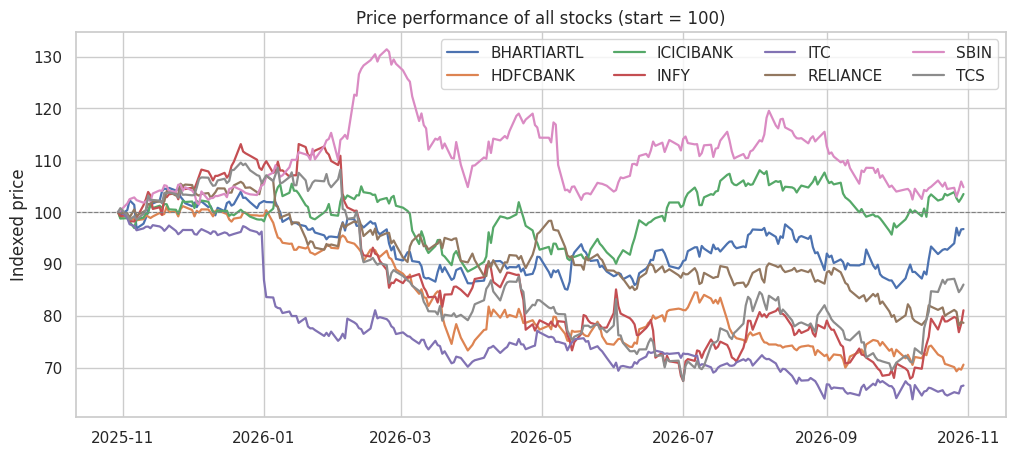

In [ ]:
# This code plots every stock's closing price indexed to 100 at the start so that stocks with different price levels can be compared.
plt.figure(figsize=(12, 5))
for s, g in full.groupby("Stock"):
    plt.plot(g["Date"], g["Close"] / g["Close"].iloc[0] * 100, label=short(s), linewidth=1.6)
plt.axhline(100, color="grey", ls="--", lw=0.8)
plt.title("Price performance of all stocks (start = 100)")
plt.ylabel("Indexed price")
plt.legend(ncol=4)
plt.show()

### **Graph 2: Candlestick Chart (Plotly)**

In [ ]:
# This code draws an interactive candlestick chart with Plotly for the last 60 sessions of one stock (green = Close above Open, red = Close below Open).
c60 = one.tail(60)
fig = go.Figure(data=[go.Candlestick(x=c60["Date"], open=c60["Open"], high=c60["High"], low=c60["Low"], close=c60["Close"],
                                     increasing_line_color=UP_COLOR, decreasing_line_color=DOWN_COLOR)])
fig.update_layout(title=f"Candlestick chart - {short(EDA_STOCK)} (last 60 sessions)", xaxis_rangeslider_visible=False, height=450)
fig.show()

### **Graph 3: Volume Bars**

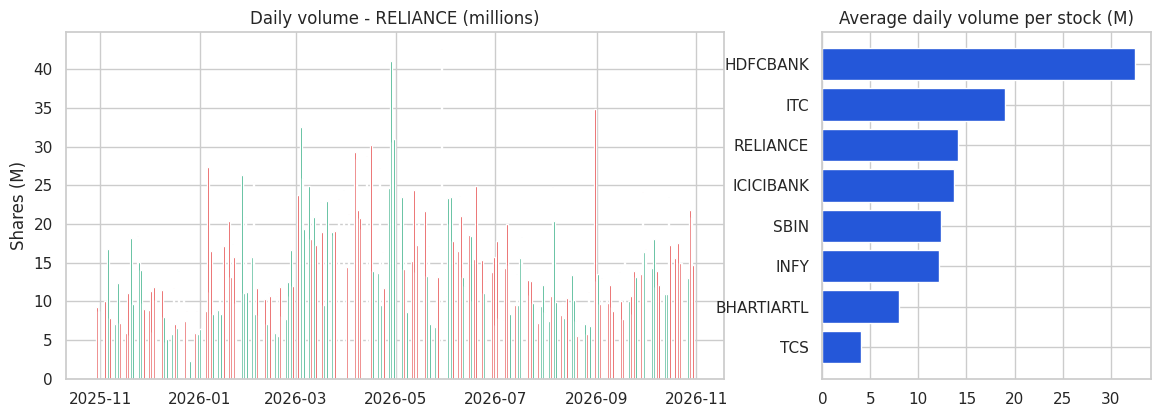

In [ ]:
# This code shows the trading volume of one stock over time as bars (green = Close above Open, red = Close below Open) and compares the average volume of all stocks.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(one["Date"], one["Volume"] / 1e6, color=np.where(one["Close"] >= one["Open"], UP_COLOR, DOWN_COLOR), width=1.0)
axes[0].set_title(f"Daily volume - {short(EDA_STOCK)} (millions)")
axes[0].set_ylabel("Shares (M)")

vol = full.groupby("Stock")["Volume"].mean().sort_values() / 1e6
axes[1].barh([short(s) for s in vol.index], vol.values, color=ACCENT)
axes[1].set_title("Average daily volume per stock (M)")
plt.show()

### **Graph 4: Moving Averages**

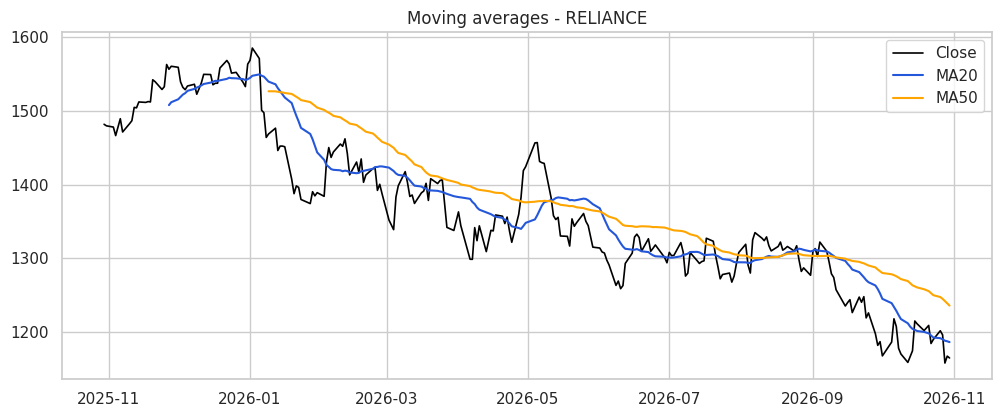

In [ ]:
# This code plots the closing price with its 20-day and 50-day moving averages to show the trend direction.
plt.figure(figsize=(12, 4.5))
plt.plot(one["Date"], one["Close"], label="Close", color="black", lw=1.2)
plt.plot(one["Date"], one["MA20"], label="MA20", color=ACCENT)
plt.plot(one["Date"], one["MA50"], label="MA50", color="orange")
plt.title(f"Moving averages - {short(EDA_STOCK)}")
plt.legend()
plt.show()

### **Graph 5: Bollinger Bands**

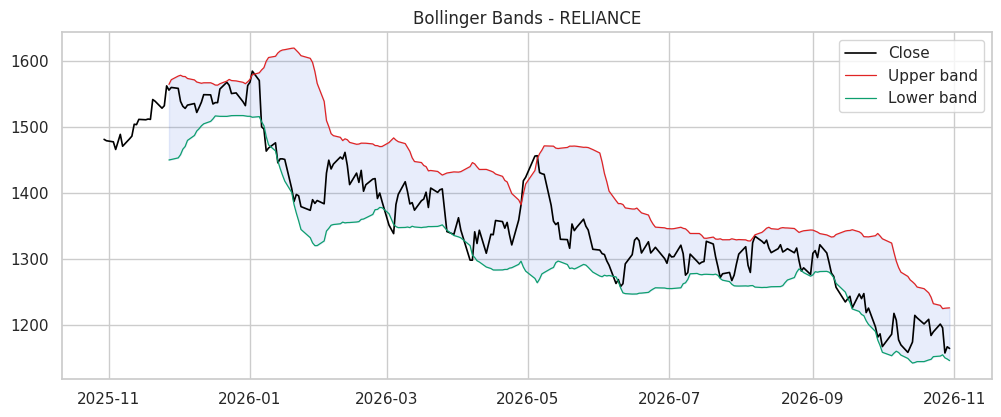

In [ ]:
# This code draws Bollinger Bands (20-day average +/- 2 standard deviations) to show volatility around the price.
plt.figure(figsize=(12, 4.5))
plt.plot(one["Date"], one["Close"], color="black", lw=1.2, label="Close")
plt.plot(one["Date"], one["BB_upper"], color=DOWN_COLOR, lw=0.9, label="Upper band")
plt.plot(one["Date"], one["BB_lower"], color=UP_COLOR, lw=0.9, label="Lower band")
plt.fill_between(one["Date"], one["BB_lower"], one["BB_upper"], alpha=0.1, color=ACCENT)
plt.title(f"Bollinger Bands - {short(EDA_STOCK)}")
plt.legend()
plt.show()

### **Graph 6: RSI (Relative Strength Index)**

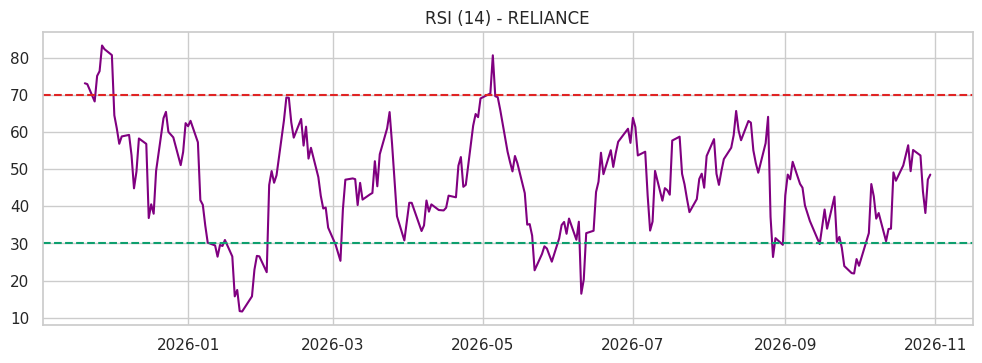

In [ ]:
# This code plots the 14-day RSI. Above 70 = overbought, below 30 = oversold.
plt.figure(figsize=(12, 3.8))
plt.plot(one["Date"], one["RSI14"], color="purple")
plt.axhline(70, color=DOWN_COLOR, ls="--")
plt.axhline(30, color=UP_COLOR, ls="--")
plt.title(f"RSI (14) - {short(EDA_STOCK)}")
plt.show()

### **Graph 7: MACD**

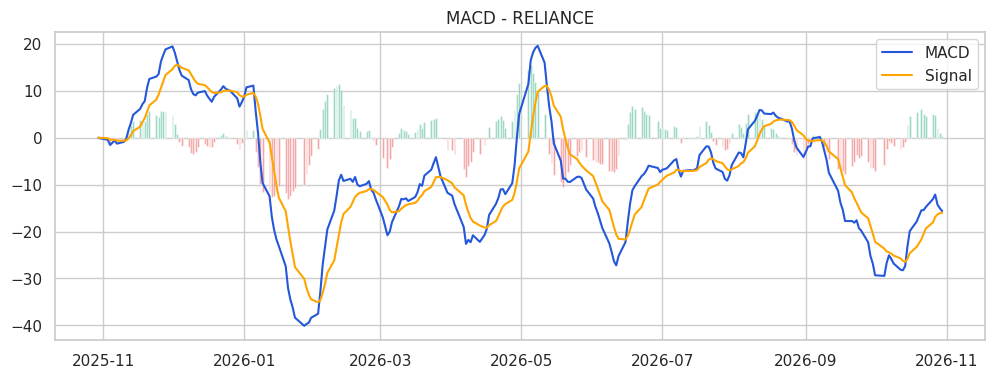

In [ ]:
# This code plots the MACD line, its signal line and the histogram (momentum indicator).
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(one["Date"], one["MACD"], label="MACD", color=ACCENT)
ax.plot(one["Date"], one["MACD_signal"], label="Signal", color="orange")
ax.bar(one["Date"], one["MACD_hist"], color=np.where(one["MACD_hist"] >= 0, UP_COLOR, DOWN_COLOR), alpha=0.5)
ax.set_title(f"MACD - {short(EDA_STOCK)}")
ax.legend()
plt.show()

### **Graph 8: Distribution of Daily Returns (Histogram + KDE)**

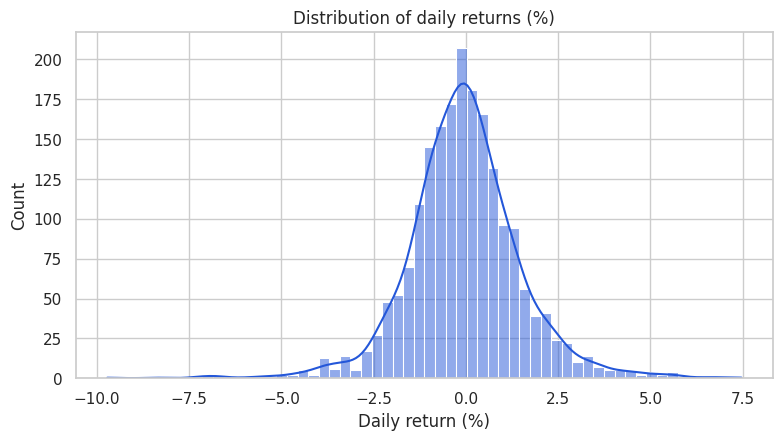

In [ ]:
# This code shows how daily percentage returns are distributed.
plt.figure(figsize=(9, 4.5))
sns.histplot(full["Return_pct"].dropna(), bins=60, kde=True, color=ACCENT)
plt.title("Distribution of daily returns (%)")
plt.xlabel("Daily return (%)")
plt.show()

### **Graph 9: Box Plot of Returns by Stock**

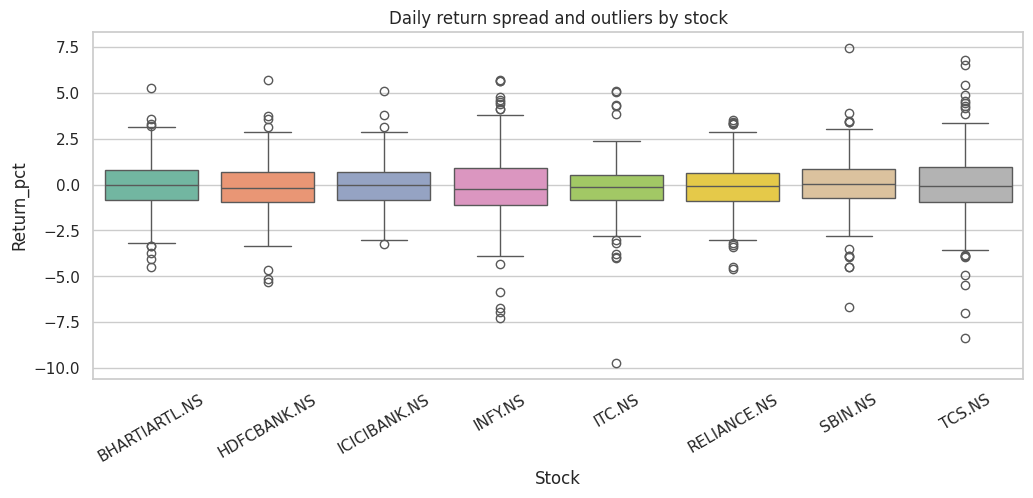

In [ ]:
# This code uses box plots to compare the spread of returns and to spot outliers for every stock.
plt.figure(figsize=(12, 4.5))
sns.boxplot(data=full, x="Stock", y="Return_pct", palette="Set2")
plt.xticks(rotation=30)
plt.title("Daily return spread and outliers by stock")
plt.show()

### **Graph 10: Violin Plot of Returns by Sector**

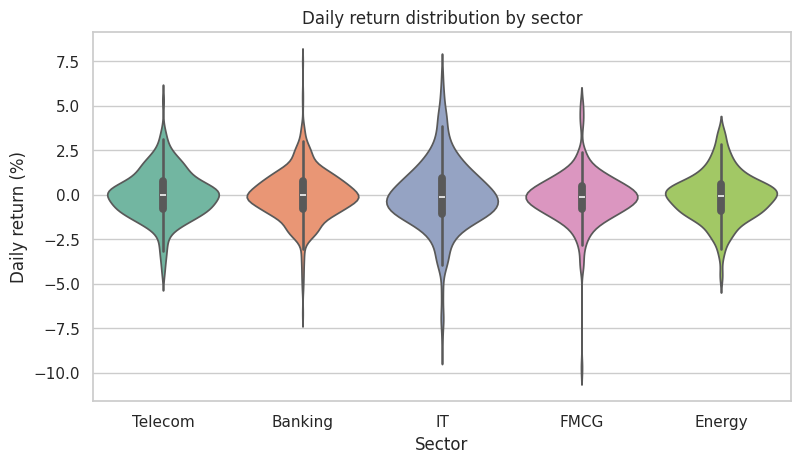

In [ ]:
# This code compares the distribution of daily returns for every sector with a violin plot.
plt.figure(figsize=(9, 4.8))
sns.violinplot(data=full, x="Sector", y="Return_pct", palette="Set2")
plt.title("Daily return distribution by sector")
plt.ylabel("Daily return (%)")
plt.show()

### **Graph 11: Correlation Heatmap**

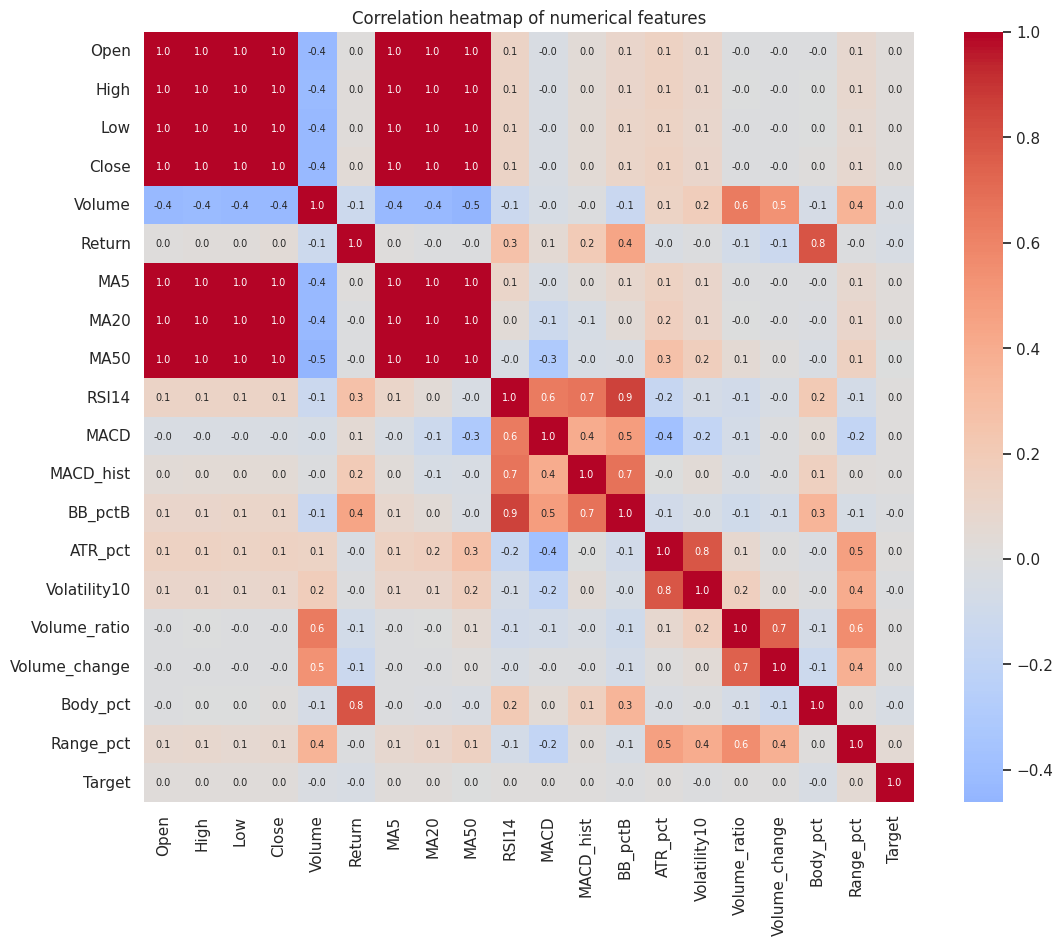

In [ ]:
# This code shows the correlation between all numerical features and the Target. (The Target is tomorrow's direction, so its correlation with every feature is expected to be small.)
corr_cols = ["Open", "High", "Low", "Close", "Volume", "Return", "MA5", "MA20", "MA50", "RSI14", "MACD", "MACD_hist",
             "BB_pctB", "ATR_pct", "Volatility10", "Volume_ratio", "Volume_change", "Body_pct", "Range_pct", "Target"]
plt.figure(figsize=(13, 10))
sns.heatmap(full[corr_cols].corr(), annot=True, fmt=".1f", annot_kws={"size": 7}, cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap of numerical features")
plt.show()

### **Graph 12: Scatter Plot - Volume vs Size of Price Move**

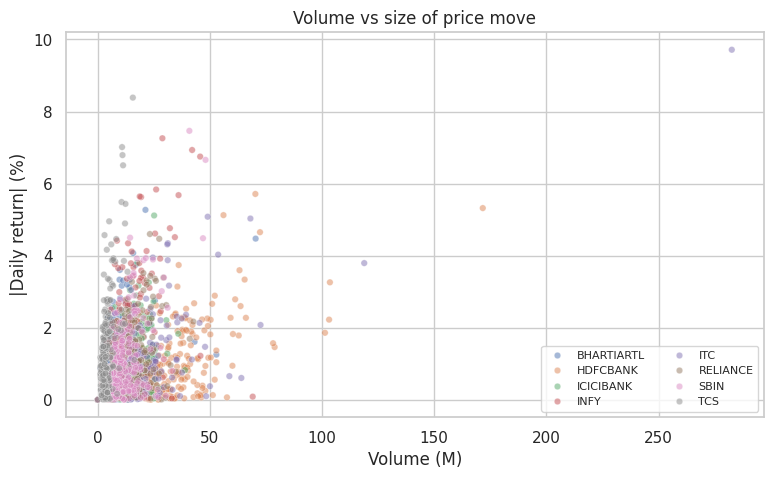

In [ ]:
# This code checks whether higher traded volume goes together with bigger price moves.
plt.figure(figsize=(9, 5))
sns.scatterplot(data=full, x=full["Volume"] / 1e6, y=full["Return_pct"].abs(), hue=full["Stock"].map(short), alpha=0.5, s=22)
plt.xlabel("Volume (M)")
plt.ylabel("|Daily return| (%)")
plt.title("Volume vs size of price move")
plt.legend(ncol=2, fontsize=8)
plt.show()

### **Graph 13: Rolling Volatility**

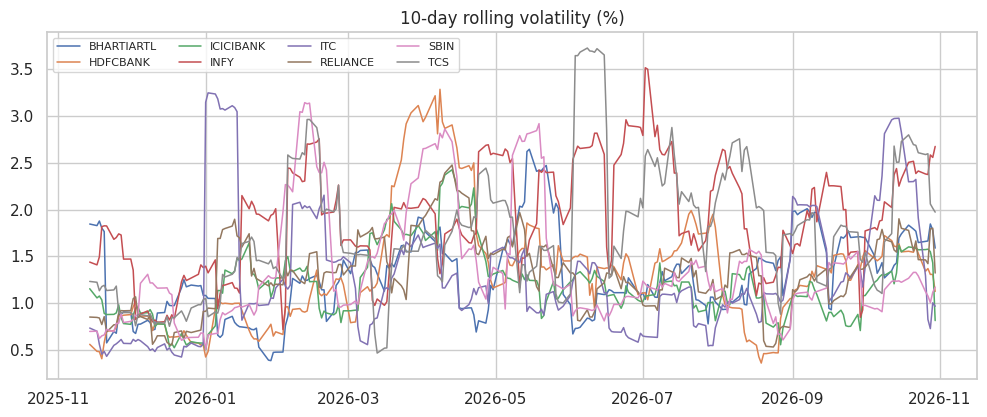

In [ ]:
# This code plots the 10-day rolling volatility (standard deviation of returns) of every stock.
plt.figure(figsize=(12, 4.5))
for s, g in full.groupby("Stock"):
    plt.plot(g["Date"], g["Volatility10"] * 100, label=short(s), lw=1.1)
plt.title("10-day rolling volatility (%)")
plt.legend(ncol=4, fontsize=8)
plt.show()

### **Graph 14: Target Class Balance (Pie + Count Plot)**

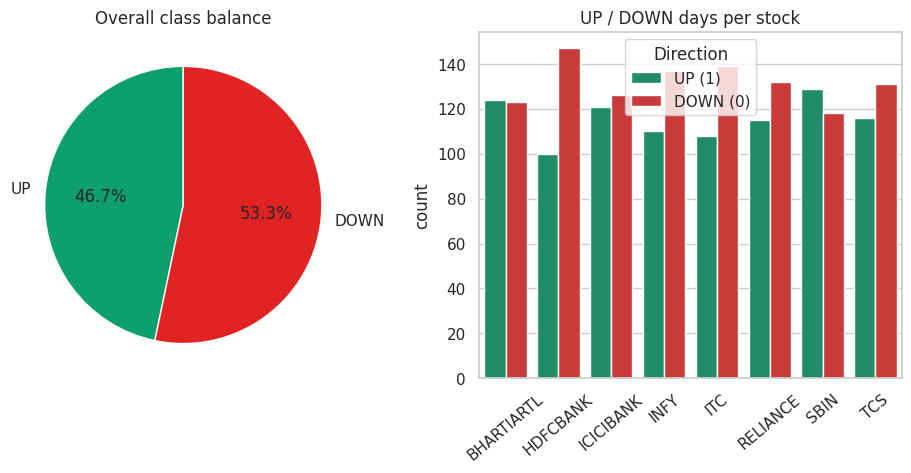

In [ ]:
# This code shows the overall UP/DOWN balance of tomorrow's direction and the balance for each stock.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cnt = full["Target"].value_counts().reindex([1, 0])
axes[0].pie(cnt, labels=["UP", "DOWN"], autopct="%1.1f%%", colors=[UP_COLOR, DOWN_COLOR], startangle=90)
axes[0].set_title("Overall class balance")
sns.countplot(data=full, x=full["Stock"].map(short), hue="Direction", hue_order=["UP (1)", "DOWN (0)"], palette=[UP_COLOR, DOWN_COLOR], ax=axes[1])
axes[1].tick_params(axis="x", rotation=40)
axes[1].set_xlabel("")
axes[1].set_title("UP / DOWN days per stock")
plt.show()

### **Graph 15: Average Return by Weekday (Heatmap)**

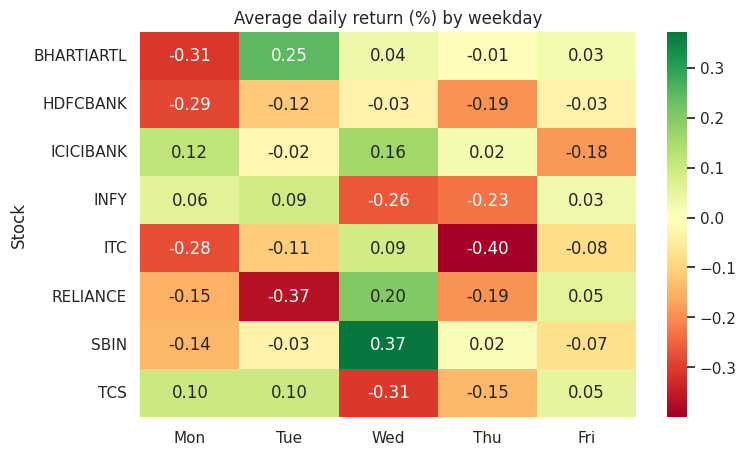

In [ ]:
# This code shows the average return for every weekday and stock.
days = ["Mon", "Tue", "Wed", "Thu", "Fri"]
pivot = full.pivot_table(index=full["Stock"].map(short), columns="DayOfWeek", values="Return_pct", aggfunc="mean")
pivot.columns = [days[i] for i in pivot.columns]

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Average daily return (%) by weekday")
plt.show()

## **Data Preprocessing and Feature Engineering**

All features below use **only information known at today's close**: today's return, candle shape and opening gap, and indicators calculated up to and including today. The label is **tomorrow's** direction, so tomorrow's data is never used as a feature.

In [ ]:
# This code builds the model features for one stock (everything is known at today's close).
def build_features(g):
    f = pd.DataFrame(index=g.index)
    for k in (0, 1, 2, 4):
        f[f"Return_lag{k}"] = g["Return"].shift(k)
    f["Body_pct"] = g["Body_pct"]
    f["Range_pct"] = g["Range_pct"]
    f["Gap_pct"] = g["Open"] / g["Close"].shift(1) - 1
    f["Close_vs_MA5"] = g["Close"] / g["MA5"] - 1
    f["Close_vs_MA20"] = g["Close"] / g["MA20"] - 1
    f["MA5_vs_MA20"] = g["MA5"] / g["MA20"] - 1
    f["RSI14"] = g["RSI14"]
    f["MACD_pct"] = g["MACD"] / g["Close"]
    f["MACD_hist_pct"] = g["MACD_hist"] / g["Close"]
    f["BB_pctB"] = g["BB_pctB"]
    f["ATR_pct"] = g["ATR_pct"]
    f["Volatility10"] = g["Volatility10"]
    f["Volume_ratio"] = g["Volume_ratio"]
    f["Volume_change"] = g["Volume_change"]
    f["Next_DayOfWeek"] = np.where(g["Date"].dt.dayofweek >= 4, 0, g["Date"].dt.dayofweek + 1)
    return f

In [ ]:
# This code creates the feature table for all stocks and removes the first rows where indicators have not warmed up yet.
feat_all = pd.concat([build_features(g) for _, g in full.groupby("Stock")])
FEATURES = list(feat_all.columns)

model_df = pd.concat([full[["Date", "Stock", "Open", "Close", "Next_Close", "Target"]], feat_all], axis=1)
model_df = model_df.replace([np.inf, -np.inf], np.nan).dropna().sort_values(["Date", "Stock"]).reset_index(drop=True)
model_df["Target"] = model_df["Target"].astype(int)

print(len(FEATURES), "features |", len(model_df), "usable rows")
print(FEATURES)
model_df.head()

19 features | 1816 usable rows
['Return_lag0', 'Return_lag1', 'Return_lag2', 'Return_lag4', 'Body_pct', 'Range_pct', 'Gap_pct', 'Close_vs_MA5', 'Close_vs_MA20', 'MA5_vs_MA20', 'RSI14', 'MACD_pct', 'MACD_hist_pct', 'BB_pctB', 'ATR_pct', 'Volatility10', 'Volume_ratio', 'Volume_change', 'Next_DayOfWeek']


,Date,Stock,Open,Close,Next_Close,Target,Return_lag0,Return_lag1,Return_lag2,Return_lag4,...,MA5_vs_MA20,RSI14,MACD_pct,MACD_hist_pct,BB_pctB,ATR_pct,Volatility10,Volume_ratio,Volume_change,Next_DayOfWeek
0,2025-11-27,BHARTIARTL.NS,2105.50,2089.31,2075.48,0,-0.005266,-0.016096,0.004413,0.002041,...,0.020088,74.804602,0.009684,0.001219,0.572016,0.015605,0.008823,0.355873,-0.897047,4
1,2025-11-27,HDFCBANK.NS,985.80,993.08,991.21,0,0.005579,0.014245,-0.009350,-0.010711,...,0.006872,65.853081,0.001966,0.001795,1.017283,0.014367,0.008619,1.310502,0.309961,4
2,2025-11-27,ICICIBANK.NS,1367.47,1380.56,1377.19,0,0.012504,0.012670,-0.007745,-0.009763,...,0.007034,67.983782,0.003777,0.001332,0.890632,0.012068,0.008450,1.262183,0.569390,4
3,2025-11-27,INFY.NS,1530.87,1533.22,1527.06,0,0.005456,0.017835,-0.011239,0.005532,...,0.021725,66.363161,0.009870,0.003085,0.888100,0.020063,0.017288,0.777345,-0.003008,4
4,2025-11-27,ITC.NS,384.74,385.50,385.45,0,0.004979,0.003742,-0.006809,0.005898,...,-0.008877,50.481155,-0.008378,-0.000253,0.346457,0.010650,0.006122,0.722366,-0.241562,4


### **Separating Features and Target Variable**

In [ ]:
# This code separates the independent variables into X and the target variable into y.
X = model_df[FEATURES]
y = model_df["Target"]
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (1816, 19) | y shape: (1816,)


### **Splitting Dataset into Training (80%) and Testing (20%) Data**

In [ ]:
# This code splits the data chronologically: the first 80% of the calendar dates are used for training and the last 20% for testing.
all_dates = np.sort(model_df["Date"].unique())
cutoff = all_dates[int(len(all_dates) * 0.8) - 1]
train_mask = model_df["Date"] <= cutoff

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]
meta_test = model_df.loc[~train_mask, ["Date", "Stock", "Open", "Close", "Next_Close"]]

print("Original Dataset Shape:", X.shape)
print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape :", X_test.shape)
print()
print("Training period:", model_df.loc[train_mask, "Date"].min().date(), "to", pd.Timestamp(cutoff).date())
print("Testing period :", model_df.loc[~train_mask, "Date"].min().date(), "to", model_df.loc[~train_mask, "Date"].max().date())
print("Training UP share:", round(y_train.mean(), 3), "| Testing UP share:", round(y_test.mean(), 3))

Original Dataset Shape: (1816, 19)
Training Feature Shape: (1448, 19)
Testing Feature Shape : (368, 19)

Training period: 2025-11-27 to 2026-08-21
Testing period : 2026-08-24 to 2026-10-29
Training UP share: 0.467 | Testing UP share: 0.448


### **Handling Outliers (clipping with training percentiles)**

In [ ]:
# This code limits extreme values to the 1st and 99th percentile of the TRAINING data (the same limits are applied to the test data, so nothing leaks).
clip_lo, clip_hi = X_train.quantile(0.01), X_train.quantile(0.99)
X_train = X_train.clip(clip_lo, clip_hi, axis=1)
X_test = X_test.clip(clip_lo, clip_hi, axis=1)

### **Feature Scaling Using StandardScaler**

In [ ]:
# This code standardizes the features (mean 0, standard deviation 1). The scaler is fitted on training data only. Inside the models, the scaler is part of a Pipeline, so every cross-validation fold is also scaled without peeking at its validation part.
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

display(X_train_scaled.describe().loc[["mean", "std"]].round(2))

,Return_lag0,Return_lag1,Return_lag2,Return_lag4,Body_pct,Range_pct,Gap_pct,Close_vs_MA5,Close_vs_MA20,MA5_vs_MA20,RSI14,MACD_pct,MACD_hist_pct,BB_pctB,ATR_pct,Volatility10,Volume_ratio,Volume_change,Next_DayOfWeek
mean,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## **Model Comparison**

We compare **11 classifiers + a baseline**.

* **Baseline** (always predict the majority class) tells us the score a model gets by pure guessing. A useful model must beat it.
* Models that need scaled input (Logistic Regression, KNN, SVM, MLP, Naive Bayes) get a `StandardScaler` inside a Pipeline.
* Validation uses **TimeSeriesSplit**: each fold trains on the past and validates on the future, like real trading.

In [ ]:
# This code lists every model together with its configuration (hyperparameters).
MODEL_SPECS = {
    "Baseline (majority)": (DummyClassifier, dict(strategy="most_frequent"), False),
    "Logistic Regression": (LogisticRegression, dict(max_iter=1000), True),
    "KNN": (KNeighborsClassifier, dict(n_neighbors=15), True),
    "Naive Bayes": (GaussianNB, dict(), True),
    "Decision Tree": (DecisionTreeClassifier, dict(max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE), False),
    "Random Forest": (RandomForestClassifier, dict(n_estimators=300, max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=-1), False),
    "Extra Trees": (ExtraTreesClassifier, dict(n_estimators=300, max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=-1), False),
    "Gradient Boosting": (GradientBoostingClassifier, dict(random_state=RANDOM_STATE), False),
    "AdaBoost": (AdaBoostClassifier, dict(random_state=RANDOM_STATE), False),
    "SVM (RBF)": (SVC, dict(probability=True, random_state=RANDOM_STATE), True),
    "Neural Net (MLP)": (MLPClassifier, dict(hidden_layer_sizes=(32, 16), max_iter=500, early_stopping=True, random_state=RANDOM_STATE), True),
}
if HAS_XGB:
    MODEL_SPECS["XGBoost"] = (XGBClassifier, dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE), False)
if HAS_LGBM:
    MODEL_SPECS["LightGBM"] = (LGBMClassifier, dict(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1), False)

def make_pipeline(cls, kwargs, scale):
    steps = ([("scaler", StandardScaler())] if scale else []) + [("model", cls(**kwargs))]
    return Pipeline(steps)

models = {name: make_pipeline(*spec) for name, spec in MODEL_SPECS.items()}

config_table = pd.DataFrame([
    {"Model": n, "Algorithm": cls.__name__, "Scaled": sc, "Configuration": ", ".join(f"{k}={v}" for k, v in kw.items()) or "defaults"}
    for n, (cls, kw, sc) in MODEL_SPECS.items()
])
display(config_table)

,Model,Algorithm,Scaled,Configuration
0,Baseline (majority),DummyClassifier,False,strategy=most_frequent
1,Logistic Regression,LogisticRegression,True,max_iter=1000
2,KNN,KNeighborsClassifier,True,n_neighbors=15
3,Naive Bayes,GaussianNB,True,defaults
4,Decision Tree,DecisionTreeClassifier,False,"max_depth=5, min_samples_leaf=10, random_state=42"
5,Random Forest,RandomForestClassifier,False,"n_estimators=300, max_depth=6, min_samples_lea..."
6,Extra Trees,ExtraTreesClassifier,False,"n_estimators=300, max_depth=6, min_samples_lea..."
7,Gradient Boosting,GradientBoostingClassifier,False,random_state=42
8,AdaBoost,AdaBoostClassifier,False,random_state=42
9,SVM (RBF),SVC,True,"probability=True, random_state=42"


### **Evaluation Metrics Used**

| Metric | What it tells us |
|---|---|
| Accuracy | % of correct UP/DOWN calls (must beat the baseline) |
| Precision / Recall / F1 | Quality of the UP calls (F1 balances both) |
| **ROC-AUC** | How well the model *ranks* UP days above DOWN days, independent of any threshold |
| **MCC** (Matthews Corr. Coef.) | One balanced score from all four cells of the confusion matrix; 0 = guessing, 1 = perfect |
| Kappa | Agreement beyond chance |

For stock direction, **accuracy alone is misleading** (a model can score ~50% by guessing). So the final choice is based on **cross-validated ROC-AUC and MCC**.

In [ ]:
# This code defines the helper functions: one that scores a fitted model on the test data (all metrics) and the cross-validation settings.
tscv = TimeSeriesSplit(n_splits=5)
cv_scoring = {"acc": "accuracy", "auc": "roc_auc", "mcc": make_scorer(matthews_corrcoef)}
baseline_acc = max(y_test.mean(), 1 - y_test.mean())

def evaluate_on_test(mdl):
    pred = mdl.predict(X_test)
    prob = mdl.predict_proba(X_test)[:, 1]
    return {"Accuracy": accuracy_score(y_test, pred),
            "Kappa": cohen_kappa_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_test, prob),
            "MCC": matthews_corrcoef(y_test, pred)}

print("Majority-class baseline accuracy on test data:", round(baseline_acc, 4))

Majority-class baseline accuracy on test data: 0.5516


### **Training and Evaluating All Models**

In [ ]:
# This code cross-validates every model on the training period, trains it on the full training data and evaluates it on the unseen test data.
rows = {}
for name, mdl in models.items():
    cvr = cross_validate(mdl, X_train, y_train, cv=tscv, scoring=cv_scoring)
    t0 = time.time()
    mdl.fit(X_train, y_train)
    fit_time = time.time() - t0
    test_scores = evaluate_on_test(mdl)
    rows[name] = {"CV_Accuracy": cvr["test_acc"].mean(), "CV_AUC": cvr["test_auc"].mean(), "CV_AUC_std": cvr["test_auc"].std(),
                  "CV_MCC": cvr["test_mcc"].mean(), **test_scores, "Train_sec": fit_time}
    print("done:", name)

results = pd.DataFrame(rows).T.sort_values("CV_AUC", ascending=False)
results["AUC_gap(CV-Test)"] = results["CV_AUC"] - results["ROC_AUC"]
display(results.round(4))

done: Baseline (majority)
done: Logistic Regression
done: KNN
done: Naive Bayes
done: Decision Tree
done: Random Forest
done: Extra Trees
done: Gradient Boosting
done: AdaBoost
done: SVM (RBF)
done: Neural Net (MLP)
done: XGBoost
done: LightGBM


,CV_Accuracy,CV_AUC,CV_AUC_std,CV_MCC,Accuracy,Kappa,Precision,Recall,F1,ROC_AUC,MCC,Train_sec,AUC_gap(CV-Test)
KNN,0.5344,0.5278,0.0365,0.0651,0.5217,0.0164,0.4593,0.3758,0.4133,0.5299,0.0167,0.0104,-0.0021
Neural Net (MLP),0.5037,0.5232,0.0440,0.0157,0.5516,0.0454,0.5000,0.2303,0.3154,0.5192,0.0530,0.2172,0.0040
Gradient Boosting,0.5187,0.5187,0.0440,0.0267,0.5543,0.0867,0.5035,0.4303,0.4641,0.5599,0.0874,1.7373,-0.0412
Logistic Regression,0.5320,0.5174,0.0510,0.0397,0.5326,0.0465,0.4765,0.4303,0.4522,0.5268,0.0467,0.0591,-0.0094
LightGBM,0.5112,0.5157,0.0224,0.0104,0.5245,0.0348,0.4684,0.4485,0.4582,0.5312,0.0349,0.1595,-0.0155
Random Forest,0.5253,0.5141,0.0383,0.0285,0.5516,0.0611,0.5000,0.3152,0.3866,0.5344,0.0652,3.1368,-0.0204
XGBoost,0.5054,0.5132,0.0098,0.0029,0.5245,0.0248,0.4643,0.3939,0.4262,0.5172,0.0251,0.3235,-0.0039
Extra Trees,0.5286,0.5103,0.0456,0.0226,0.5408,-0.0005,0.4474,0.1030,0.1675,0.5096,-0.0007,0.5531,0.0007
Naive Bayes,0.5021,0.5011,0.0270,-0.0156,0.5109,0.0134,0.4556,0.4667,0.4611,0.5023,0.0134,0.0152,-0.0012
SVM (RBF),0.5154,0.5007,0.0283,0.0124,0.5245,0.0112,0.4569,0.3212,0.3772,0.5351,0.0116,1.0020,-0.0344


### **Comparing the Models Visually**

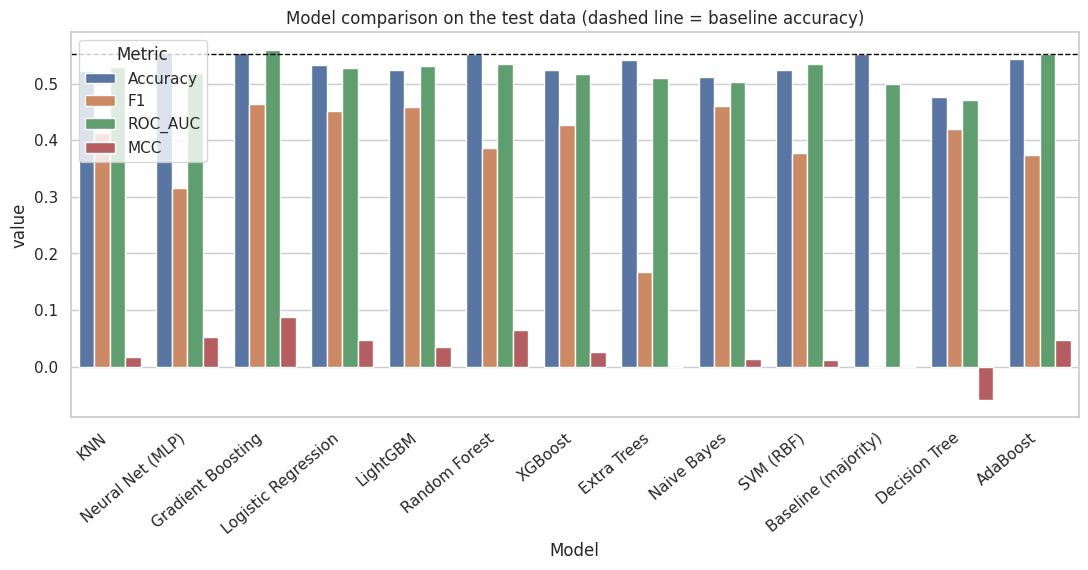

In [ ]:
# This code plots Accuracy, F1, ROC-AUC and MCC of every model. The dashed line is the baseline accuracy.
plot_df = results.reset_index().rename(columns={"index": "Model"}).melt(id_vars="Model", value_vars=["Accuracy", "F1", "ROC_AUC", "MCC"], var_name="Metric")

plt.figure(figsize=(13, 5))
sns.barplot(data=plot_df, x="Model", y="value", hue="Metric", palette="deep")
plt.axhline(baseline_acc, color="black", ls="--", lw=1)
plt.xticks(rotation=40, ha="right")
plt.title("Model comparison on the test data (dashed line = baseline accuracy)")
plt.show()

## **Hyperparameter Tuning of Every Model**

Every model (except the baseline) is tuned with `RandomizedSearchCV` + `TimeSeriesSplit`, so all models compete on equal terms. If only some models were tuned, those models would have an unfair advantage in the comparison.

In [ ]:
# This code defines the parameter search space for every model.
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "KNN": {"model__n_neighbors": [5, 11, 21, 31], "model__weights": ["uniform", "distance"]},
    "Naive Bayes": {"model__var_smoothing": np.logspace(-10, -6, 5)},
    "Decision Tree": {"model__max_depth": [2, 3, 4, 5, 8], "model__min_samples_leaf": [5, 10, 20, 40]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [3, 5, 8], "model__min_samples_leaf": [5, 10, 20]},
    "Extra Trees": {"model__n_estimators": [200, 400], "model__max_depth": [3, 5, 8], "model__min_samples_leaf": [5, 10, 20]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [2, 3]},
    "AdaBoost": {"model__n_estimators": [50, 100, 200], "model__learning_rate": [0.05, 0.1, 0.5, 1.0]},
    "SVM (RBF)": {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1]},
    "Neural Net (MLP)": {"model__hidden_layer_sizes": [(16,), (32, 16), (64, 32)], "model__alpha": [1e-4, 1e-3, 1e-2]},
    "XGBoost": {"model__n_estimators": [100, 300], "model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.05, 0.1]},
    "LightGBM": {"model__n_estimators": [100, 300], "model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.05, 0.1], "model__num_leaves": [7, 15]},
}

In [ ]:
# This code tunes every model (except the baseline) with the same search, so all models compete on equal terms, and prints the best configuration found for each.
tuned = {}
for name in models:
    if name.startswith("Baseline"):
        continue
    grid = param_grids[name]
    size = int(np.prod([len(v) for v in grid.values()]))
    search = RandomizedSearchCV(models[name], grid, n_iter=min(10, size), cv=TimeSeriesSplit(n_splits=3),
                                scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"\n{name}\n  best configuration : {search.best_params_}\n  search CV ROC-AUC  : {search.best_score_:.4f}")


Logistic Regression
  best configuration : {'model__C': 1}
  search CV ROC-AUC  : 0.5166

KNN
  best configuration : {'model__weights': 'uniform', 'model__n_neighbors': 31}
  search CV ROC-AUC  : 0.5122

Naive Bayes
  best configuration : {'model__var_smoothing': np.float64(1e-10)}
  search CV ROC-AUC  : 0.4973

Decision Tree
  best configuration : {'model__min_samples_leaf': 5, 'model__max_depth': 4}
  search CV ROC-AUC  : 0.5215

Random Forest
  best configuration : {'model__n_estimators': 400, 'model__min_samples_leaf': 10, 'model__max_depth': 3}
  search CV ROC-AUC  : 0.5112

Extra Trees
  best configuration : {'model__n_estimators': 400, 'model__min_samples_leaf': 5, 'model__max_depth': 8}
  search CV ROC-AUC  : 0.5090

Gradient Boosting
  best configuration : {'model__n_estimators': 200, 'model__max_depth': 2, 'model__learning_rate': 0.05}
  search CV ROC-AUC  : 0.5084

AdaBoost
  best configuration : {'model__n_estimators': 200, 'model__learning_rate': 0.05}
  search CV ROC-AUC

Default against tuned settings (same cross-validation, same test data):


,Default_CV_AUC,Tuned_CV_AUC,Default_Test_AUC,Tuned_Test_AUC,Default_Accuracy,Tuned_Accuracy
Neural Net (MLP),0.5232,0.5236,0.5192,0.5235,0.5516,0.5380
Gradient Boosting,0.5187,0.5229,0.5599,0.5435,0.5543,0.5435
Extra Trees,0.5103,0.5222,0.5096,0.5051,0.5408,0.5408
LightGBM,0.5157,0.5196,0.5312,0.5381,0.5245,0.5435
KNN,0.5278,0.5193,0.5299,0.5173,0.5217,0.5326
Logistic Regression,0.5174,0.5174,0.5268,0.5268,0.5326,0.5326
Random Forest,0.5141,0.5142,0.5344,0.5375,0.5516,0.5353
XGBoost,0.5132,0.5128,0.5172,0.5537,0.5245,0.5380
Decision Tree,0.4977,0.5123,0.4713,0.4724,0.4755,0.4457
SVM (RBF),0.5007,0.5032,0.5351,0.5210,0.5245,0.5516


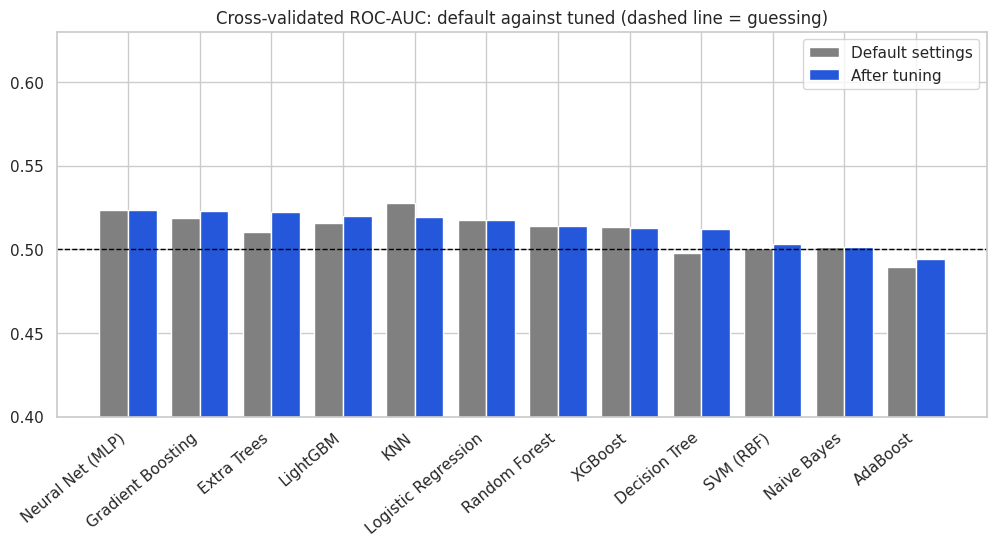

In [ ]:
# This code scores every tuned model exactly like the default models (5 time-ordered folds, then the unseen test data), so the default table and the tuned table can be compared directly.
tuned_rows = {}
for name, search in tuned.items():
    est = search.best_estimator_
    cvr = cross_validate(est, X_train, y_train, cv=tscv, scoring=cv_scoring)
    tuned_rows[name] = {"CV_Accuracy": cvr["test_acc"].mean(), "CV_AUC": cvr["test_auc"].mean(), "CV_AUC_std": cvr["test_auc"].std(),
                        "CV_MCC": cvr["test_mcc"].mean(), **evaluate_on_test(est), "Train_sec": search.refit_time_}
tuned_results = pd.DataFrame(tuned_rows).T.sort_values("CV_AUC", ascending=False)

compare = pd.DataFrame({"Default_CV_AUC": results.loc[tuned_results.index, "CV_AUC"], "Tuned_CV_AUC": tuned_results["CV_AUC"],
                        "Default_Test_AUC": results.loc[tuned_results.index, "ROC_AUC"], "Tuned_Test_AUC": tuned_results["ROC_AUC"],
                        "Default_Accuracy": results.loc[tuned_results.index, "Accuracy"], "Tuned_Accuracy": tuned_results["Accuracy"]})
print("Default against tuned settings (same cross-validation, same test data):")
display(compare.round(4))

plt.figure(figsize=(12, 5))
pos = np.arange(len(compare))
plt.bar(pos - 0.2, compare["Default_CV_AUC"], width=0.4, label="Default settings", color="grey")
plt.bar(pos + 0.2, compare["Tuned_CV_AUC"], width=0.4, label="After tuning", color=ACCENT)
plt.axhline(0.5, color="black", ls="--", lw=1)
plt.xticks(pos, compare.index, rotation=40, ha="right")
plt.ylim(0.4, max(compare["Tuned_CV_AUC"].max(), 0.6) + 0.03)
plt.title("Cross-validated ROC-AUC: default against tuned (dashed line = guessing)")
plt.legend()
plt.show()

## **Selecting the Best Model**

### **Selection rule**

The best model is the one with the highest **cross-validated ROC-AUC** (measured only on the training period, across several past/future folds). We use this instead of test accuracy because:

1. **Accuracy is threshold dependent and misleading** when classes are almost balanced - guessing already gives ~50%.
2. **ROC-AUC** measures whether the model really ranks UP days above DOWN days, whatever threshold is used.
3. **MCC** uses all four cells of the confusion matrix and stays near 0 for a model that only guesses; it is used as a second check.
4. Choosing on cross-validation (not on the test set) keeps the test set a fair, **unseen** final exam.
5. We also check **stability** (small standard deviation across folds) and the **gap between CV and test AUC** (a big gap = overfitting).
6. Because the choice is made on cross-validation, the selected model is first on that score by construction. The test scores (ROC-AUC, accuracy, F1, MCC) come from only about 370 unseen rows, so they move by a few points by chance. They are reported, but they are not used to choose.

In [ ]:
# This code selects the model with the highest cross-validated ROC-AUC after tuning, out of all the tuned models.
best_name = tuned_results["CV_AUC"].idxmax()
best_model = tuned[best_name].best_estimator_

print("SELECTED MODEL :", best_name)
print("Configuration  :", tuned[best_name].best_params_)
print()
print("Leaderboard after tuning (ranked by cross-validated ROC-AUC):")
display(tuned_results[["CV_AUC", "CV_AUC_std", "ROC_AUC", "Accuracy", "F1", "MCC"]].round(4))

SELECTED MODEL : Neural Net (MLP)
Configuration  : {'model__hidden_layer_sizes': (32, 16), 'model__alpha': 0.01}

Leaderboard after tuning (ranked by cross-validated ROC-AUC):


,CV_AUC,CV_AUC_std,ROC_AUC,Accuracy,F1,MCC
Neural Net (MLP),0.5236,0.0442,0.5235,0.5380,0.3145,0.0233
Gradient Boosting,0.5229,0.0211,0.5435,0.5435,0.4207,0.0572
Extra Trees,0.5222,0.0386,0.5051,0.5408,0.2555,0.0175
LightGBM,0.5196,0.0259,0.5381,0.5435,0.3488,0.0415
KNN,0.5193,0.0386,0.5173,0.5326,0.4110,0.0351
Logistic Regression,0.5174,0.0510,0.5268,0.5326,0.4522,0.0467
Random Forest,0.5142,0.0367,0.5375,0.5353,0.1896,-0.0103
XGBoost,0.5128,0.0304,0.5537,0.5380,0.3885,0.0395
Decision Tree,0.5123,0.0223,0.4724,0.4457,0.4302,-0.1043
SVM (RBF),0.5032,0.0379,0.5210,0.5516,0.0000,0.0000


## **Final Evaluation of the Selected Model**

### **Predicting Test Data Output**

In [ ]:
# This code predicts the class labels and the probability of UP for the unseen test data.
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

### **Comparing Actual and Predicted Values**

In [ ]:
# This code displays the actual class, the predicted class, the probability of UP and whether each prediction is correct.
comparison = pd.DataFrame({
    "Date": meta_test["Date"].dt.date,
    "Stock": meta_test["Stock"].map(short),
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Probability_UP": y_prob.round(3)
})
comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]
comparison.head(20)

,Date,Stock,Actual,Predicted,Probability_UP,Correct
1448,2026-08-24,BHARTIARTL,1,0,0.413,False
1449,2026-08-24,HDFCBANK,0,0,0.452,True
1450,2026-08-24,ICICIBANK,1,0,0.401,False
1451,2026-08-24,INFY,1,0,0.439,False
1452,2026-08-24,ITC,1,0,0.422,False
1453,2026-08-24,RELIANCE,1,0,0.491,False
1454,2026-08-24,SBIN,1,0,0.465,False
1455,2026-08-24,TCS,1,0,0.422,False
1456,2026-08-25,BHARTIARTL,0,0,0.434,True
1457,2026-08-25,HDFCBANK,0,1,0.526,False


### **Generating Confusion Matrix**

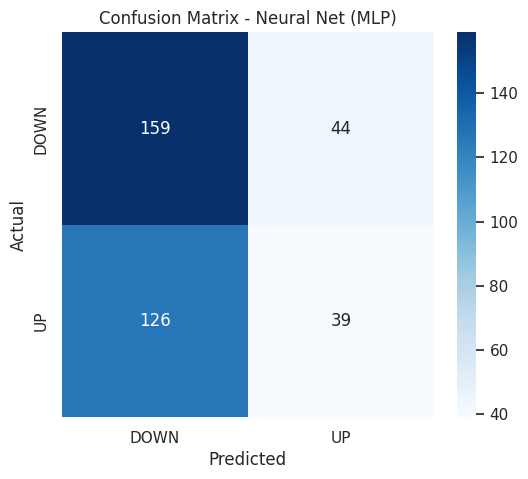

In [ ]:
# This code generates a confusion matrix to summarize correct and incorrect predictions.
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["DOWN", "UP"], yticklabels=["DOWN", "UP"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

### **Calculating Model Performance Metrics**

In [ ]:
# This code calculates Accuracy, Kappa, Precision, Recall, F1 Score, ROC-AUC and MCC of the selected model and compares accuracy with the baseline.
final_scores = evaluate_on_test(best_model)
metrics_table = pd.DataFrame({"Metric": list(final_scores.keys()), "Value": list(final_scores.values())})
display(metrics_table.round(4))

print("Baseline accuracy (always guess majority class):", round(baseline_acc, 4))
print("Improvement over baseline:", round(final_scores["Accuracy"] - baseline_acc, 4))
print()
print(classification_report(y_test, y_pred, target_names=["DOWN", "UP"], zero_division=0))

,Metric,Value
0,Accuracy,0.5380
1,Kappa,0.0206
2,Precision,0.4699
3,Recall,0.2364
4,F1,0.3145
5,ROC_AUC,0.5235
6,MCC,0.0233


Baseline accuracy (always guess majority class): 0.5516
Improvement over baseline: -0.0136

              precision    recall  f1-score   support

        DOWN       0.56      0.78      0.65       203
          UP       0.47      0.24      0.31       165

    accuracy                           0.54       368
   macro avg       0.51      0.51      0.48       368
weighted avg       0.52      0.54      0.50       368



### **ROC Curve**

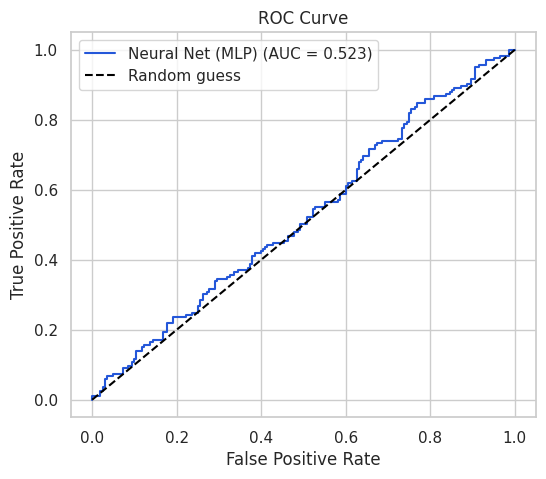

In [ ]:
# This code plots the ROC curve (True Positive Rate against False Positive Rate). The dashed diagonal is random guessing.
fpr, tpr, threshold = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"{best_name} (AUC = {final_scores['ROC_AUC']:.3f})", color=ACCENT)
plt.plot([0, 1], [0, 1], "--", color="black", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

### **Which Features Drive the Prediction?**

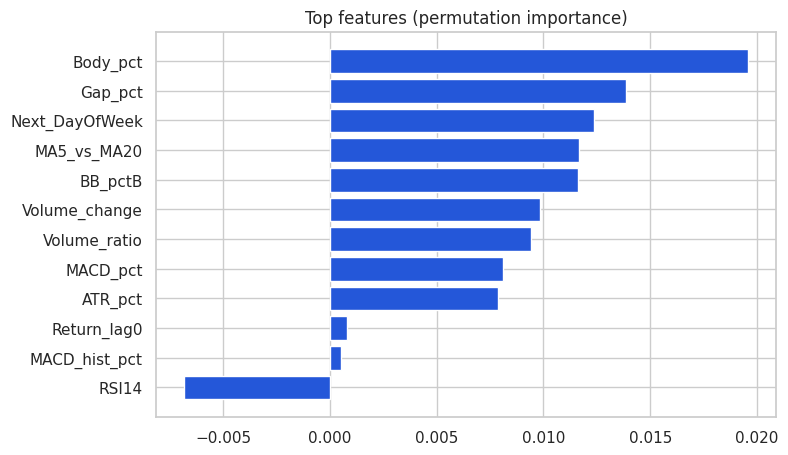

Most influential features: ['Body_pct', 'Gap_pct', 'Next_DayOfWeek']


In [ ]:
# This code measures how much the ROC-AUC drops when each feature is shuffled (permutation importance). A bigger drop = a more important feature.
imp = permutation_importance(best_model, X_test, y_test, n_repeats=10, scoring="roc_auc", random_state=RANDOM_STATE)
imp_df = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(12)

plt.figure(figsize=(8, 5))
plt.barh(imp_df.index, imp_df.values, color=ACCENT)
plt.title("Top features (permutation importance)")
plt.show()
print("Most influential features:", list(imp_df.index[::-1][:3]))

### **Accuracy for Each Stock**

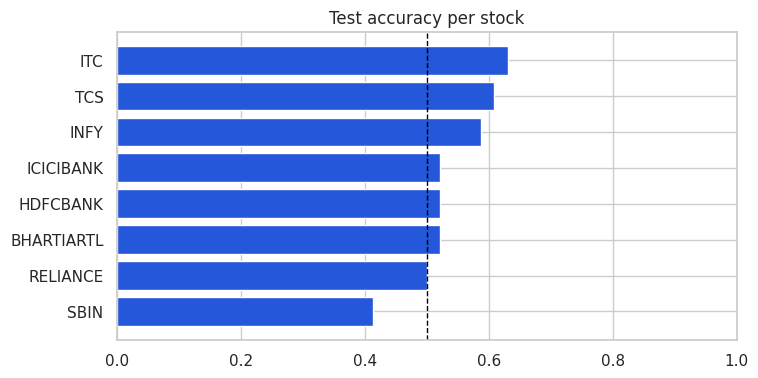

In [ ]:
# This code checks whether the model works for every stock or only for some of them.
per_stock = pd.DataFrame({"Stock": meta_test["Stock"].map(short).values, "ok": (y_pred == y_test.values)}).groupby("Stock")["ok"].mean().sort_values()

plt.figure(figsize=(8, 4))
plt.barh(per_stock.index, per_stock.values, color=ACCENT)
plt.axvline(0.5, color="black", ls="--", lw=1)
plt.xlim(0, 1)
plt.title("Test accuracy per stock")
plt.show()

### **Back-test: Does the Model Make Money?**

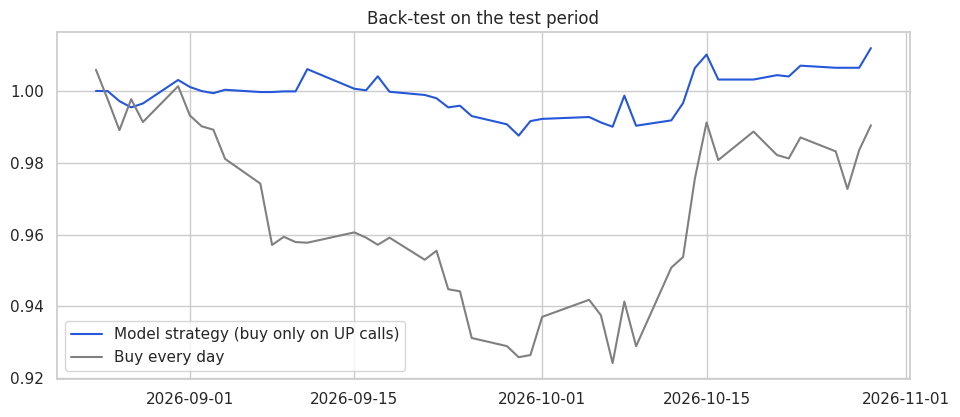

In [ ]:
# This code simulates a simple strategy on the test period: buy at today's close only when the model predicts UP for tomorrow and sell at tomorrow's close (equal weight, no costs).
bt = meta_test.copy()
bt["next_ret"] = bt["Next_Close"] / bt["Close"] - 1
bt["strategy"] = np.where(y_pred == 1, bt["next_ret"], 0.0)
daily = bt.groupby("Date")[["next_ret", "strategy"]].mean()

plt.figure(figsize=(11, 4.5))
plt.plot(daily.index, (1 + daily["strategy"]).cumprod(), label="Model strategy (buy only on UP calls)", color=ACCENT)
plt.plot(daily.index, (1 + daily["next_ret"]).cumprod(), label="Buy every day", color="grey")
plt.title("Back-test on the test period")
plt.legend()
plt.show()

## **Why Is This Model the Best Choice for UP / DOWN Prediction?**

In [ ]:
# This code explains the selection using the actual numbers of this run and a short note about the selected algorithm.
MODEL_NOTES = {
    "Logistic Regression": "A linear model that outputs a probability of UP. It uses very few parameters, so it is hard to overfit a short, noisy history, and its coefficients are easy to explain. Caveat: it can only draw a straight decision boundary.",
    "KNN": "Classifies a day by voting among the most similar past days, so it makes no assumption about the shape of the data. Caveat: with many features, distances become less meaningful and noise affects it easily.",
    "Naive Bayes": "A fast probabilistic model that works with small data. Caveat: it assumes the features are independent, while indicators such as RSI and MACD are related.",
    "Decision Tree": "Learns simple if-then rules that are easy to explain. Caveat: a single tree has high variance and can memorize noise.",
    "Random Forest": "Averages many trees, which cuts variance and handles non-linear feature interactions and outliers well - a strong, stable choice for tabular data.",
    "Extra Trees": "Like Random Forest but with extra randomness in the splits, giving smoother, lower-variance predictions on noisy data.",
    "Gradient Boosting": "Builds trees one after another, each fixing the errors of the previous ones. Very strong on tabular data; kept shallow and slow here to limit overfitting.",
    "AdaBoost": "Boosts very shallow trees (stumps) and focuses on the hard examples; the shallow trees keep the variance low on noisy data.",
    "SVM (RBF)": "A maximum-margin classifier with a flexible curved boundary; works well in moderate dimensions. Caveat: sensitive to noise and slower to train.",
    "Neural Net (MLP)": "A flexible network that can learn non-linear combinations of indicators. Our configuration uses early stopping and an L2 penalty (alpha) to limit overfitting. Caveat: it normally needs more data than a one-year history provides.",
    "XGBoost": "Regularized gradient boosting, a standard top performer on tabular data when depth and learning rate are kept small.",
    "LightGBM": "Fast gradient boosting with leaf-wise tree growth; strong on tabular data but can overfit small samples unless kept small.",
}
board = tuned_results[["CV_AUC"]].sort_values("CV_AUC", ascending=False)
second = board["CV_AUC"].iloc[1]

print(f"Selected model          : {best_name}")
print(f"Cross-validated AUC     : {board.loc[best_name, 'CV_AUC']:.4f}  (next best candidate: {second:.4f})")
print(f"Test ROC-AUC / MCC      : {final_scores['ROC_AUC']:.4f} / {final_scores['MCC']:.4f}")
print(f"Test accuracy           : {final_scores['Accuracy']:.4f}  vs baseline {baseline_acc:.4f}")
print(f"Gap between CV and test AUC: {board.loc[best_name, 'CV_AUC'] - final_scores['ROC_AUC']:+.4f}  (small = generalises well)")
print()
print("About the selected algorithm:")
print(" ", MODEL_NOTES.get(best_name, ""))
print()
if final_scores["Accuracy"] <= baseline_acc + 0.02:
    print("NOTE: accuracy is close to the baseline. Tomorrow's direction is very hard to predict from past prices (markets are close to a random walk), so a result near 50-55% is expected and is itself an honest finding. Differences between the models are then within the noise of the test set.")
else:
    print("The model beats the guessing baseline, so it has found a real pattern (see the feature importance chart for what it relies on).")

Selected model          : Neural Net (MLP)
Cross-validated AUC     : 0.5236  (next best candidate: 0.5229)
Test ROC-AUC / MCC      : 0.5235 / 0.0233
Test accuracy           : 0.5380  vs baseline 0.5516
Gap between CV and test AUC: +0.0002  (small = generalises well)

About the selected algorithm:
  A flexible network that can learn non-linear combinations of indicators. Our configuration uses early stopping and an L2 penalty (alpha) to limit overfitting. Caveat: it normally needs more data than a one-year history provides.

NOTE: accuracy is close to the baseline. Tomorrow's direction is very hard to predict from past prices (markets are close to a random walk), so a result near 50-55% is expected and is itself an honest finding. Differences between the models are then within the noise of the test set.


## **Predicting the Trend**

The selected model is refitted on **all** labelled data (train + test) so the prediction uses the most recent history. The scores reported above come from the train-only model.

To predict **tomorrow's** trend we only need the **stock**: its latest data is converted into the features and the model returns the probability of UP.

In [ ]:
# This code refits the selected model on all labelled data and defines a function that predicts tomorrow's UP/DOWN trend of a stock from its latest data.
final_model = clone(best_model).fit(pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))

def predict_next(stock):
    g = df[df["Stock"] == stock].sort_values("Date")[["Date", "Stock", "Open", "High", "Low", "Close", "Volume"]]
    g2 = compute_indicators(g)
    x_row = build_features(g2).iloc[[-1]][FEATURES].clip(clip_lo, clip_hi, axis=1)
    p_up = float(final_model.predict_proba(x_row)[0, 1])
    last = g.iloc[-1]
    return {"direction": "UP" if p_up >= 0.5 else "DOWN", "p_up": p_up,
            "date": last["Date"] + pd.offsets.BDay(1), "last_date": last["Date"], "last_close": float(last["Close"])}

In [ ]:
# This code predicts tomorrow's trend for every stock.
table = []
for s in stocks:
    r = predict_next(s)
    table.append({"Stock": short(s), "Latest_data": r["last_date"].date(), "Prediction_for": r["date"].date(),
                  "Tomorrow": r["direction"], "Probability_UP": round(r["p_up"], 3), "Last_close": round(r["last_close"], 2)})
display(pd.DataFrame(table))

,Stock,Latest_data,Prediction_for,Tomorrow,Probability_UP,Last_close
0,BHARTIARTL,2026-10-30,2026-11-02,DOWN,0.371,1973.70
1,HDFCBANK,2026-10-30,2026-11-02,DOWN,0.413,692.80
2,ICICIBANK,2026-10-30,2026-11-02,DOWN,0.378,1398.00
3,INFY,2026-10-30,2026-11-02,DOWN,0.344,1185.00
4,ITC,2026-10-30,2026-11-02,DOWN,0.357,265.60
5,RELIANCE,2026-10-30,2026-11-02,UP,0.509,1164.90
6,SBIN,2026-10-30,2026-11-02,DOWN,0.351,961.85
7,TCS,2026-10-30,2026-11-02,DOWN,0.404,2502.60


In [ ]:
# This code predicts the trend for one chosen stock: change the stock name and run the cell again.
stock_input = "TCS.NS"

r = predict_next(stock_input)
print(f"Stock              : {short(stock_input)}")
print(f"Latest data        : {r['last_date'].date()} (close {r['last_close']:.2f})")
print(f"Prediction for     : {r['date'].date()}")
print(f"Tomorrow's trend   : {r['direction']}  (probability of UP = {r['p_up'] * 100:.1f}%)")

Stock              : TCS
Latest data        : 2026-10-30 (close 2502.60)
Prediction for     : 2026-11-02
Tomorrow's trend   : DOWN  (probability of UP = 40.4%)


## **Model Deployment (Optional - Flask + ngrok)**

This section follows sir's method: save the model, create a Flask API with CORS, and expose it with an ngrok tunnel so that an HTML page can call it.

* The API cells run without an ngrok token (the routes are only defined).
* The server starts **only if `NGROK_TOKEN` is filled in**. Get your own free token from https://dashboard.ngrok.com and paste it below. Leave it empty to skip deployment.

In [ ]:
# This code saves the trained model and the preprocessing information to disk.
joblib.dump(final_model, "model.pkl")
joblib.dump({"features": FEATURES, "clip_lo": clip_lo, "clip_hi": clip_hi, "model_name": best_name}, "model_meta.pkl")
print("Saved: model.pkl and model_meta.pkl")

Saved: model.pkl and model_meta.pkl


In [ ]:
# This code installs the API libraries and creates a Flask app with three endpoints: /api/meta, /api/predict (POST) and /get_eda.
!pip install -q flask flask-cors pyngrok

import io, base64
from flask import Flask, request, jsonify
from flask_cors import CORS
from matplotlib.figure import Figure
from pyngrok import ngrok

app = Flask(__name__)
CORS(app)  # allows an HTML page hosted elsewhere to call this API

@app.route("/api/meta", methods=["GET"])
def api_meta():
    out = []
    for s in stocks:
        h = df[df["Stock"] == s].sort_values("Date").tail(60)
        out.append({"symbol": s, "last_close": round(float(h["Close"].iloc[-1]), 2),
                    "history": [round(float(v), 2) for v in h["Close"]],
                    "dates": [d.strftime("%Y-%m-%d") for d in h["Date"]]})
    return jsonify({"model": best_name, "accuracy": round(final_scores["Accuracy"], 4),
                    "baseline": round(float(baseline_acc), 4), "auc": round(final_scores["ROC_AUC"], 4), "stocks": out})

@app.route("/api/predict", methods=["POST"])
def api_predict():
    try:
        data = request.get_json()
        r = predict_next(data["stock"])
        row = full[full["Stock"] == data["stock"]].sort_values("Date").iloc[-1]
        return jsonify({"direction": r["direction"], "p_up": r["p_up"], "date": str(r["date"].date()),
                        "open": r["last_close"], "last_close": r["last_close"],
                        "signals": [{"label": "Today's return", "value": f"{row['Return'] * 100:+.2f}%"},
                                    {"label": "RSI (14)", "value": f"{row['RSI14']:.0f}"},
                                    {"label": "5d vs 20d average", "value": f"{(row['MA5'] / row['MA20'] - 1) * 100:+.2f}%"},
                                    {"label": "Volume vs 20d avg", "value": f"{row['Volume_ratio']:.2f}x"}]})
    except Exception as e:
        return jsonify({"status": "error", "message": str(e)}), 400

@app.route("/get_eda", methods=["GET"])
def get_eda():
    def to_b64(fig):
        buf = io.BytesIO()
        fig.savefig(buf, format="png", bbox_inches="tight")
        return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode("utf-8")

    fig1 = Figure(figsize=(5, 3.5))
    ax1 = fig1.subplots()
    ax1.hist(full["Return_pct"].dropna(), bins=50, color=ACCENT)
    ax1.set_title("Distribution of daily returns (%)")

    fig2 = Figure(figsize=(5, 3.5))
    ax2 = fig2.subplots()
    cnt = full["Target"].value_counts().reindex([1, 0])
    ax2.bar(["UP", "DOWN"], cnt.values, color=[UP_COLOR, DOWN_COLOR])
    ax2.set_title("Class balance")
    return jsonify({"status": "success", "histogram": to_b64(fig1), "class_balance": to_b64(fig2)})

### **Extra API routes for the web page: live Yahoo Finance data and OHLCV input**

* `/api/live` downloads the latest real session of a stock from Yahoo Finance so the page can auto-fill the Open, High, Low, Close and Volume boxes.
* `/api/models` returns the model comparison (every model's scores, configuration, tuning result, the classification of each stock, the confusion matrix and ROC points). Raw probabilities are calibrated (shrunk toward 50%) because models are overconfident.
* `/api/nextday` checks every model against what really happened on the trading days after the training data ended (real prices from Yahoo Finance), and `/api/models` can return the default or the tuned version of every model.
* `/api/eda` draws the EDA graphs for one stock or for all stocks (dark or light theme) and returns them with a plain-language insight for each graph.
* `/api/predict_ohlcv` takes those five values (typed by the user or fetched live), adds them as the latest session to the stock's history, rebuilds the 19 features and returns tomorrow's UP / DOWN call.

In [ ]:
# This code adds the extra API routes used by the HTML page: /api/live (latest real session from Yahoo Finance), /api/predict_ohlcv (tomorrow's trend from typed or live OHLCV values, with calibrated confidence), /api/models (model comparison, default or tuned), /api/nextday (did each model call the days after the training data correctly?) and /api/eda (EDA graphs with plain-language insights).
!pip install -q yfinance
import yfinance as yf

def fetch_live(stock, period="6mo"):
    h = yf.Ticker(stock).history(period=period, interval="1d", auto_adjust=True)
    if h.empty:
        raise ValueError("Yahoo Finance returned no data for " + str(stock))
    h = h.reset_index()
    h["Date"] = pd.to_datetime(h["Date"]).dt.tz_localize(None).dt.normalize()
    return h[["Date", "Open", "High", "Low", "Close", "Volume"]].dropna().reset_index(drop=True)

def predict_from_history(hist, session):
    if len(hist) < 30:
        raise ValueError("At least 30 earlier trading days are needed to calculate the indicators")
    g2 = compute_indicators(pd.concat([hist, pd.DataFrame([session])], ignore_index=True))
    x_row = build_features(g2).iloc[[-1]][FEATURES].clip(clip_lo, clip_hi, axis=1)
    if x_row.isna().values.any():
        raise ValueError("Could not calculate all features from the values given")
    return float(final_model.predict_proba(x_row)[0, 1]), g2

@app.route("/api/live", methods=["GET"])
def api_live():
    try:
        h = fetch_live(request.args.get("stock"))
        last = h.iloc[-1]
        tail = h.tail(60)
        return jsonify({"date": str(last["Date"].date()), "open": round(float(last["Open"]), 2), "high": round(float(last["High"]), 2),
                        "low": round(float(last["Low"]), 2), "close": round(float(last["Close"]), 2), "volume": int(last["Volume"]),
                        "history": [round(float(v), 2) for v in tail["Close"]],
                        "dates": [d.strftime("%Y-%m-%d") for d in tail["Date"]], "source": "Yahoo Finance"})
    except Exception as e:
        return jsonify({"status": "error", "message": "Could not fetch live data: " + str(e)}), 502

@app.route("/api/predict_ohlcv", methods=["POST"])
def api_predict_ohlcv():
    try:
        d = request.get_json()
        stock = d["stock"]
        v = {k: float(d[k]) for k in ("open", "high", "low", "close", "volume")}
        if min(v["open"], v["high"], v["low"], v["close"]) <= 0 or v["volume"] < 0:
            raise ValueError("Prices must be positive and volume cannot be negative")
        if v["high"] < max(v["open"], v["close"], v["low"]) or v["low"] > min(v["open"], v["close"], v["high"]):
            raise ValueError("High must be the highest price and Low the lowest")

        if d.get("source") == "live":
            hist = fetch_live(stock)
            history_source = "Yahoo Finance (live)"
        else:
            hist = df[df["Stock"] == stock][["Date", "Open", "High", "Low", "Close", "Volume"]]
            history_source = "training dataset"
        hist = hist.sort_values("Date").reset_index(drop=True)
        if hist.empty:
            raise ValueError("No history found for " + str(stock))

        session_date = pd.Timestamp(d["date"]) if d.get("date") else hist["Date"].iloc[-1] + pd.offsets.BDay(1)
        hist = hist[hist["Date"] < session_date]
        session = {"Date": session_date, "Open": v["open"], "High": v["high"], "Low": v["low"], "Close": v["close"], "Volume": v["volume"]}

        p_up, g2 = predict_from_history(hist, session)
        global _final_a
        if _final_a is None:
            _final_a = oof_temperature(best_model)
        p_cal = float(calibrate([p_up], _final_a)[0])
        row = g2.iloc[-1]
        tail = g2.tail(60)
        return jsonify({"direction": "UP" if p_up >= 0.5 else "DOWN", "p_up": p_cal, "p_raw": p_up, "temp": round(_final_a, 3),
                        "session_date": str(session_date.date()),
                        "predicted_for": str((session_date + pd.offsets.BDay(1)).date()),
                        "last_close": v["close"], "history": [round(float(x), 2) for x in tail["Close"]], "dates": [d_.strftime("%Y-%m-%d") for d_ in tail["Date"]],
                        "history_source": history_source,
                        "signals": [{"label": "Today's return", "value": f"{row['Return'] * 100:+.2f}%"},
                                    {"label": "RSI (14)", "value": f"{row['RSI14']:.0f}"},
                                    {"label": "5d vs 20d average", "value": f"{(row['MA5'] / row['MA20'] - 1) * 100:+.2f}%"},
                                    {"label": "Volume vs 20d avg", "value": f"{row['Volume_ratio']:.2f}x"}]})
    except Exception as e:
        return jsonify({"status": "error", "message": str(e)}), 400


from sklearn.linear_model import LogisticRegression as _LR
_final_a = None

def oof_temperature(mdl):

    ps, ys = [], []
    for tr, va in TimeSeriesSplit(n_splits=5).split(X_train):
        m = clone(mdl).fit(X_train.iloc[tr], y_train.iloc[tr])
        ps.append(m.predict_proba(X_train.iloc[va])[:, 1])
        ys.append(y_train.iloc[va].values)
    p = np.clip(np.concatenate(ps), 0.001, 0.999)
    z = np.log(p / (1 - p)).reshape(-1, 1)
    a = float(_LR(fit_intercept=False, C=1e6).fit(z, np.concatenate(ys)).coef_[0, 0])
    return min(max(a, 0.05), 1.0)

def calibrate(p, a):
    p = np.clip(np.asarray(p, dtype=float), 0.001, 0.999)
    return 1 / (1 + np.exp(-a * np.log(p / (1 - p))))

_models_cache = {}

def est_dict(version):
    # the models shown in the comparison: default settings, or the tuned version of every model
    if version == "tuned":
        d = {n: s.best_estimator_ for n, s in tuned.items()}
        d["Baseline (majority)"] = models["Baseline (majority)"]
        return d
    return models

def models_extra(version="tuned"):
    if version not in _models_cache:
        latest = [build_features(compute_indicators(df[df["Stock"] == s].sort_values("Date")[["Date", "Open", "High", "Low", "Close", "Volume"]])).iloc[[-1]][FEATURES] for s in stocks]
        X_tom = pd.concat(latest).clip(clip_lo, clip_hi, axis=1)
        st = meta_test["Stock"].values
        out = {}
        for name, mdl in est_dict(version).items():
            pred = mdl.predict(X_test)
            prob = mdl.predict_proba(X_test)[:, 1]
            acc = pd.Series(pred == y_test.values).groupby(st).mean()
            fpr, tpr, _ = roc_curve(y_test, prob)
            k = np.linspace(0, len(fpr) - 1, 20).astype(int)
            a = oof_temperature(mdl)
            p_raw = mdl.predict_proba(X_tom)[:, 1]
            p_tom = calibrate(p_raw, a)
            out[name] = {"temp": round(a, 3),
                         "by_stock": {s: {"acc": round(float(acc[s]), 3), "p_up": round(float(pc), 4), "p_raw": round(float(pr), 4), "up": bool(pr >= 0.5)} for s, pc, pr in zip(stocks, p_tom, p_raw)},
                         "cm": confusion_matrix(y_test, pred).tolist(),
                         "roc": [[round(float(fpr[i]), 3), round(float(tpr[i]), 3)] for i in k]}
        _models_cache[version] = out
    return _models_cache[version]

@app.route("/api/models", methods=["GET"])
def api_models():
    version = request.args.get("version", "tuned")
    if version not in ("default", "tuned"):
        version = "tuned"
    num = lambda x: None if pd.isna(x) else round(float(x), 4)
    cfg = config_table.set_index("Model")["Configuration"].to_dict()
    extra = models_extra(version)
    table = results if version == "default" else pd.concat([tuned_results, results.loc[["Baseline (majority)"]]])
    rows = []
    for name, r in table.iterrows():
        config = cfg.get(name, "")
        if version == "tuned" and name in tuned:
            kw = dict(MODEL_SPECS[name][1])
            kw.update({k.replace("model__", ""): v for k, v in tuned[name].best_params_.items()})
            config = ", ".join(f"{k}={v}" for k, v in kw.items())
        row = {"model": name, "config": config, "cv_acc": num(r["CV_Accuracy"]), "cv_auc": num(r["CV_AUC"]),
               "cv_auc_std": num(r["CV_AUC_std"]), "cv_mcc": num(r["CV_MCC"]), "accuracy": num(r["Accuracy"]),
               "kappa": num(r["Kappa"]), "precision": num(r["Precision"]), "recall": num(r["Recall"]), "f1": num(r["F1"]),
               "auc": num(r["ROC_AUC"]), "mcc": num(r["MCC"]), "train_sec": num(r["Train_sec"]), "tuned": None}
        row.update(extra[name])
        if name in tuned:
            row["tuned"] = {"cv_auc": num(tuned_results.loc[name, "CV_AUC"]),
                            "params": {k.replace("model__", ""): str(v) for k, v in tuned[name].best_params_.items()}}
        rows.append(row)
    return jsonify({"selected": best_name, "baseline": num(baseline_acc), "stocks": stocks, "version": version, "rows": rows})

# ---------- next-day check: did each model call the days AFTER the training data correctly? (real prices from Yahoo Finance) ----------
import time as _time
_live_cache = {}

def live_history(stock):
    t = _time.time()
    if stock not in _live_cache or t - _live_cache[stock][0] > 600:
        _live_cache[stock] = (t, fetch_live(stock, period="6mo").sort_values("Date").reset_index(drop=True))
    return _live_cache[stock][1]

@app.route("/api/nextday", methods=["GET"])
def api_nextday():
    try:
        version = request.args.get("version", "tuned")
        if version not in ("default", "tuned"):
            version = "tuned"
        ests = est_dict(version)
        temps = {n: models_extra(version)[n]["temp"] for n in ests}
        last_date = df["Date"].max()
        window = sorted({str(d.date()) for d in live_history(stocks[0])["Date"] if d > last_date})[:4]   # only the first four trading days after the training data (2 to 5 Nov 2026)
        keys, rows_x, actual = [], [], {}
        for s in stocks:
            h = live_history(s)
            f = build_features(compute_indicators(h))[FEATURES].clip(clip_lo, clip_hi, axis=1)
            for k in range(1, len(h)):
                if str(h["Date"].iloc[k].date()) in window and not f.iloc[k - 1].isna().any():
                    day = str(h["Date"].iloc[k].date())
                    keys.append((s, day))
                    rows_x.append(f.iloc[k - 1])
                    actual[(s, day)] = int(h["Close"].iloc[k] > h["Close"].iloc[k - 1])
        days = sorted({d for _, d in keys})
        out = {"version": version, "last_date": str(last_date.date()), "days": days, "stocks": stocks, "selected": best_name, "rows": [], "actual": {}}
        if not days:
            return jsonify(out)
        Xn = pd.DataFrame(rows_x)[FEATURES]
        idx = {k: i for i, k in enumerate(keys)}
        out["actual"] = {s: [actual.get((s, d)) for d in days] for s in stocks}
        for name, est in ests.items():
            p_raw = est.predict_proba(Xn)[:, 1]
            p_cal = calibrate(p_raw, temps[name])
            out["rows"].append({"model": name,
                                "up": {s: [int(p_raw[idx[(s, d)]] >= 0.5) if (s, d) in idx else None for d in days] for s in stocks},
                                "p": {s: [round(float(p_cal[idx[(s, d)]]), 4) if (s, d) in idx else None for d in days] for s in stocks}})
        return jsonify(out)
    except Exception as e:
        return jsonify({"status": "error", "message": "Could not run the next-day check: " + str(e)}), 502

# ---------- EDA graphs for the web page (drawn with matplotlib and sent as base64 SVG like sir's /get_eda sends PNG; dark or light to match the page) ----------
import matplotlib
import matplotlib.dates as mdates
import threading
matplotlib.rcParams["svg.fonttype"] = "path"
PALETTES = {"dark": dict(BG="#151A23", GRID="#262C38", TXT="#E8EAED", MUT="#8B93A1", GOLD="#D4AF6A", GRN="#34C77B", RED="#F0616D", BLUE="#7C8CFF"),
            "light": dict(BG="#FBFAF7", GRID="#E3DFD5", TXT="#22252B", MUT="#6B7280", GOLD="#9A7424", GRN="#1E9E5B", RED="#D64550", BLUE="#4A5BD4")}
BG, GRID, TXT, MUT, GOLD, GRN, RED, BLUE = PALETTES["dark"].values()
_eda_cache, _eda_lock = {}, threading.Lock()

def set_theme(name):
    global BG, GRID, TXT, MUT, GOLD, GRN, RED, BLUE
    BG, GRID, TXT, MUT, GOLD, GRN, RED, BLUE = PALETTES[name].values()

def _fig(w=11, h=4.6, dates=False):
    fig = Figure(figsize=(w, h), facecolor=BG)
    ax = fig.subplots()
    ax.set_facecolor(BG)
    ax.tick_params(colors=TXT, labelsize=11)
    for sp in ax.spines.values():
        sp.set_color(GRID)
    ax.grid(color=GRID, linewidth=0.7)
    if dates:
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    return fig, ax

def _legend(ax):
    ax.legend(facecolor=BG, edgecolor=GRID, labelcolor=TXT, fontsize=10.5, ncol=4)

DAYS_FULL = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

def build_eda(stock):
    graphs = []
    def add(fig, title, how, says):
        fig.tight_layout()
        buf = io.BytesIO()
        fig.savefig(buf, format="svg", facecolor=fig.get_facecolor())
        w_, h_ = fig.get_size_inches()
        graphs.append({"title": title, "how": how, "says": says, "wide": bool(w_ >= 10), "image": "data:image/svg+xml;base64," + base64.b64encode(buf.getvalue()).decode("utf-8")})
    names = [short(s) for s in stocks]

    if stock == "ALL":
        ch = (full.groupby("Stock")["Close"].last() / full.groupby("Stock")["Close"].first() - 1) * 100
        sd = full.groupby("Stock")["Return_pct"].std()
        vol = full.groupby("Stock")["Volume"].mean().sort_values() / 1e6
        fig, ax = _fig(dates=True)
        for s, g in full.groupby("Stock"):
            ax.plot(g["Date"], g["Close"] / g["Close"].iloc[0] * 100, lw=1.6, label=short(s))
        ax.axhline(100, color=TXT, ls="--", lw=0.8); _legend(ax)
        add(fig, "Price performance of all stocks (start = 100)",
            "Every stock starts at 100, so they can be compared fairly. A line above 100 has gained since the start, below 100 has lost.",
            f"{int((ch > 0).sum())} of {len(ch)} stocks ended the year higher than they began. The best was {short(ch.idxmax())} ({ch.max():+.1f}%) and the weakest was {short(ch.idxmin())} ({ch.min():+.1f}%).")
        fig, ax = _fig(h=4.2); ax.barh([short(s) for s in vol.index], vol.values, color=GOLD)
        add(fig, "Average daily volume (millions of shares)",
            "A longer bar means more shares change hands on an average day. Busy stocks are easier to buy and sell.",
            f"{short(vol.index[-1])} is the most traded stock ({vol.iloc[-1]:.1f} million shares a day) and {short(vol.index[0])} the least ({vol.iloc[0]:.1f} million).")
        fig, ax = _fig(); bp = ax.boxplot([full[full["Stock"] == s]["Return_pct"].dropna() for s in stocks], patch_artist=True,
                                          medianprops=dict(color=TXT), whiskerprops=dict(color=MUT), capprops=dict(color=MUT),
                                          flierprops=dict(markerfacecolor=RED, markeredgecolor=RED, markersize=4))
        for p in bp["boxes"]:
            p.set_facecolor(GOLD); p.set_alpha(0.8)
        ax.set_xticklabels(names, rotation=0, fontsize=10)
        big = int((full["Return_pct"].abs() > 5).sum())
        add(fig, "Daily return spread by stock (%)",
            "The box holds the middle half of all days and the line inside is the typical day. Tall boxes and far-away dots mean a riskier stock.",
            f"{short(sd.idxmax())} has the widest swings (about {sd.max():.2f}% a day) and {short(sd.idxmin())} the narrowest ({sd.min():.2f}%). Only {big} stock-days moved by more than 5% in either direction.")
        secs = sorted(full["Sector"].unique()); ssd = full.groupby("Sector")["Return_pct"].std()
        fig, ax = _fig(); vp = ax.violinplot([full[full["Sector"] == c]["Return_pct"].dropna() for c in secs], showmedians=True)
        for b_ in vp["bodies"]:
            b_.set_facecolor(GOLD); b_.set_alpha(0.7)
        ax.set_xticks(range(1, len(secs) + 1)); ax.set_xticklabels(secs, fontsize=10)
        add(fig, "Daily returns by sector",
            "A wider part of a shape means more days with that return. A taller shape means a more volatile sector.",
            f"{ssd.idxmax()} is the most volatile sector ({ssd.max():.2f}% a day) and {ssd.idxmin()} the calmest ({ssd.min():.2f}%).")
        cols = ["Return", "Body_pct", "Range_pct", "RSI14", "MACD_hist", "BB_pctB", "ATR_pct", "Volatility10", "Volume_ratio", "Target"]
        cm_ = full[cols].corr(); ct = cm_["Target"].drop("Target")
        fig, ax = _fig(w=8.5, h=6.2); ax.grid(False); ax.imshow(cm_, cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=9); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=9)
        for i in range(len(cols)):
            for j in range(len(cols)):
                ax.text(j, i, f"{cm_.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8, color="black")
        add(fig, "Correlation heatmap",
            "Red means two measures rise and fall together, blue means they move opposite, white means no link. The last row shows how each measure relates to tomorrow's direction (Target).",
            f"The strongest link with tomorrow's direction is {ct.abs().idxmax()} at {ct[ct.abs().idxmax()]:+.2f}, which is very weak. No single indicator predicts tomorrow on its own.")
        p = full.groupby("Stock")["Target"].mean()
        fig, ax = _fig(h=4.2); ax.bar(names, p.values, color=GRN); ax.bar(names, 1 - p.values, bottom=p.values, color=RED)
        ax.axhline(0.5, color=TXT, ls="--", lw=0.9)
        add(fig, "Days followed by a higher close (green) or lower close (red)",
            "Each bar is 100% of a stock's days. The green part is the share of days whose next close was higher. The dashed line is 50%, a perfectly balanced stock.",
            f"{short(p.idxmax())} rose after {p.max() * 100:.0f}% of its days, the most of all stocks, while {short(p.idxmin())} rose after only {p.min() * 100:.0f}%. Across all stocks the share is {full['Target'].mean() * 100:.1f}%.")
        piv = full.pivot_table(index=full["Stock"].map(short), columns="DayOfWeek", values="Return_pct", aggfunc="mean")
        wd = full.groupby("DayOfWeek")["Return_pct"].mean()
        fig, ax = _fig(w=9, h=5); ax.grid(False); ax.imshow(piv.values, cmap="RdYlGn", vmin=-0.6, vmax=0.6, aspect="auto")
        ax.set_xticks(range(5)); ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri"], fontsize=10); ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index, fontsize=10)
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color="black")
        add(fig, "Average return (%) by weekday",
            "Green means the stock was on average up on that weekday, red means down. The numbers are the average daily return in percent.",
            f"Across all stocks {DAYS_FULL[int(wd.idxmax())]} was the strongest day ({wd.max():+.2f}% on average) and {DAYS_FULL[int(wd.idxmin())]} the weakest ({wd.min():+.2f}%). With one year of data this is only a hint.")
        lastv = full.groupby("Stock")["Volatility10"].last() * 100
        fig, ax = _fig(dates=True)
        for s, g in full.groupby("Stock"):
            ax.plot(g["Date"], g["Volatility10"] * 100, lw=1.2, label=short(s))
        _legend(ax)
        add(fig, "10-day volatility (%)",
            "Volatility is how much a price swings day to day. Peaks mark turbulent weeks, low stretches mark calm ones.",
            f"Right now {short(lastv.idxmax())} is the most volatile ({lastv.max():.2f}% a day) and {short(lastv.idxmin())} the calmest ({lastv.min():.2f}%).")
        tiles = [{"label": "Best 1-year move", "value": f"{short(ch.idxmax())} {ch.max():+.1f}%", "tone": "up" if ch.max() > 0 else "down"},
                 {"label": "Worst 1-year move", "value": f"{short(ch.idxmin())} {ch.min():+.1f}%", "tone": "down" if ch.min() < 0 else "up"},
                 {"label": "Most volatile", "value": f"{short(sd.idxmax())} {sd.max():.2f}% / day", "tone": ""},
                 {"label": "Most traded", "value": f"{short(vol.index[-1])} {vol.iloc[-1]:.1f}M", "tone": ""}]
        read = (f"Over the year {short(ch.idxmax())} did best ({ch.max():+.1f}%) and {short(ch.idxmin())} did worst ({ch.min():+.1f}%). "
                f"{short(sd.idxmax())} moves the most from day to day. Only {full['Target'].mean() * 100:.1f}% of days were followed by a higher close, so the market was slightly weak overall.")
    else:
        g = full[full["Stock"] == stock].sort_values("Date").reset_index(drop=True)
        last = g.iloc[-1]
        c = g.tail(60).reset_index(drop=True); x = np.arange(len(c))
        col = [GRN if a_ >= b_ else RED for a_, b_ in zip(c["Close"], c["Open"])]
        fig, ax = _fig(); ax.vlines(x, c["Low"], c["High"], color=col, linewidth=1.2)
        ax.bar(x, (c["Close"] - c["Open"]).abs().clip(lower=0.01), bottom=np.minimum(c["Open"], c["Close"]), color=col, width=0.65)
        ax.set_xticks(x[::6]); ax.set_xticklabels(c["Date"].dt.strftime("%d %b").iloc[::6])
        ng = int((c["Close"] >= c["Open"]).sum())
        add(fig, "Candlestick chart (last 60 sessions)",
            "Each candle is one day. The body runs from the opening price to the closing price. Green means it closed higher than it opened, red means lower. The thin lines show the day's high and low.",
            f"Of the last 60 sessions, {ng} closed higher than they opened (green) and {60 - ng} closed lower (red). The price moved from about {c['Open'].iloc[0]:.0f} to {c['Close'].iloc[-1]:.0f} ({(c['Close'].iloc[-1] / c['Open'].iloc[0] - 1) * 100:+.1f}%), with a high of {c['High'].max():.0f} and a low of {c['Low'].min():.0f}.")
        fig, ax = _fig(dates=True); ax.plot(g["Date"], g["Close"], color=TXT, lw=1.4, label="Close")
        ax.plot(g["Date"], g["MA20"], color=GOLD, lw=1.6, label="20-day average"); ax.plot(g["Date"], g["MA50"], color=BLUE, lw=1.6, label="50-day average"); _legend(ax)
        v20 = (last["Close"] / last["MA20"] - 1) * 100; v50 = (last["Close"] / last["MA50"] - 1) * 100
        m = g.dropna(subset=["MA50"]); share = (m["Close"] > m["MA50"]).mean() * 100
        add(fig, "Closing price with moving averages",
            "A moving average smooths out daily noise. Price above both averages, with the 20-day line above the 50-day line, is an uptrend. Price below both is a downtrend.",
            f"The latest close is {abs(v20):.1f}% {'above' if v20 >= 0 else 'below'} the 20-day average and {abs(v50):.1f}% {'above' if v50 >= 0 else 'below'} the 50-day average. The 20-day line is {'above' if last['MA20'] >= last['MA50'] else 'below'} the 50-day line, so momentum is {'rising' if last['MA20'] >= last['MA50'] else 'falling'}. The price was above its 50-day average on {share:.0f}% of days.")
        fig, ax = _fig(dates=True); ax.plot(g["Date"], g["Close"], color=TXT, lw=1.4, label="Close")
        ax.plot(g["Date"], g["BB_upper"], color=RED, lw=1.1, label="Upper band"); ax.plot(g["Date"], g["BB_lower"], color=GRN, lw=1.1, label="Lower band")
        ax.fill_between(g["Date"], g["BB_lower"], g["BB_upper"], color=BLUE, alpha=0.12); _legend(ax)
        pb = last["BB_pctB"]; wid = ((g["BB_upper"] - g["BB_lower"]) / g["MA20"] * 100).dropna(); wnow = wid.iloc[-1]
        add(fig, "Bollinger Bands",
            "The bands sit two standard deviations above and below the 20-day average. Wide bands mean a volatile market, narrow bands a calm one. A price touching a band looks stretched.",
            f"Today the price sits {pb * 100:.0f}% of the way from the lower band to the upper band, {'near the upper band, so it looks stretched upward' if pb > 0.8 else ('in the upper half of the bands, so it is leaning high but not stretched' if pb > 0.6 else ('around the middle, so nothing looks stretched' if pb >= 0.4 else ('in the lower half of the bands, so it is leaning low but not stretched' if pb >= 0.2 else 'near the lower band, so it looks stretched downward')))}. The bands are {wnow:.1f}% wide, {'wider' if wnow > wid.mean() else 'narrower'} than the yearly average of {wid.mean():.1f}%.")
        fig, ax = _fig(dates=True); ax.bar(g["Date"], g["Volume"] / 1e6, color=np.where(g["Close"] >= g["Open"], GRN, RED), width=1.0)
        bi = g["Volume"].idxmax()
        add(fig, "Trading volume (millions of shares)",
            "Each bar is one day's traded volume. Green days closed higher than they opened, red days lower. Big moves on high volume are more meaningful than on low volume.",
            f"An average day trades {g['Volume'].mean() / 1e6:.1f} million shares. The latest session traded {last['Volume'] / 1e6:.1f} million ({last['Volume'] / g['Volume'].mean():.1f}x the average). The busiest day was {g.loc[bi, 'Date'].strftime('%d %b %Y')} with {g.loc[bi, 'Volume'] / 1e6:.1f} million shares.")
        fig, ax = _fig(dates=True); ax.plot(g["Date"], g["RSI14"], color=GOLD, lw=1.6)
        ax.axhline(70, color=RED, ls="--", lw=1); ax.axhline(30, color=GRN, ls="--", lw=1); ax.set_ylim(0, 100)
        rsi = last["RSI14"]; rs = "overbought, it may cool down" if rsi > 70 else ("oversold, it may bounce back" if rsi < 30 else "in the neutral zone")
        add(fig, "RSI (14-day Relative Strength Index)",
            "RSI scores recent gains against recent losses from 0 to 100. Above 70 is called overbought (the stock rose fast and may cool down). Below 30 is oversold (it fell fast and may bounce).",
            f"RSI is {rsi:.0f} now, {rs}. During the year it went above 70 on {int((g['RSI14'] > 70).sum())} days and below 30 on {int((g['RSI14'] < 30).sum())} days.")
        fig, ax = _fig(dates=True); ax.plot(g["Date"], g["MACD"], color=BLUE, lw=1.4, label="MACD"); ax.plot(g["Date"], g["MACD_signal"], color=GOLD, lw=1.4, label="Signal line")
        ax.bar(g["Date"], g["MACD_hist"], color=np.where(g["MACD_hist"] >= 0, GRN, RED), alpha=0.5, width=1.0); _legend(ax)
        hs = np.sign(g["MACD_hist"].dropna()); cross = int((hs.diff().abs() > 0).sum())
        add(fig, "MACD (momentum)",
            "MACD compares a fast and a slow moving average. When the blue MACD line crosses above the gold signal line, momentum is turning up. Crossing below means momentum is turning down.",
            f"MACD is {'above' if last['MACD_hist'] >= 0 else 'below'} its signal line right now, so short-term momentum is {'rising' if last['MACD_hist'] >= 0 else 'falling'}. The two lines crossed {cross} times during the year, which shows how often the mood changed.")
        fig, ax = _fig(); ax.hist(g["Return_pct"].dropna(), bins=40, color=GOLD, alpha=0.9); ax.axvline(0, color=TXT, lw=1)
        calm = (g["Return_pct"].abs() <= 1.5).mean() * 100
        add(fig, "Distribution of daily returns (%)",
            "The bars count how many days ended with each percentage change. Bars to the right of the white line are up days, bars to the left are down days.",
            f"About {calm:.0f}% of days moved by less than 1.5% in either direction. The best day was {g['Return_pct'].max():+.1f}% and the worst {g['Return_pct'].min():+.1f}%. Big days are rare, so most of the time the stock moves quietly.")
        fig, ax = _fig(dates=True); ax.plot(g["Date"], g["Volatility10"] * 100, color=RED, lw=1.6)
        vnow = last["Volatility10"] * 100; vavg = (g["Volatility10"] * 100).mean()
        add(fig, "10-day volatility (%)",
            "Volatility is how much the price swings from day to day over the last 10 sessions. Higher means bigger swings.",
            f"Recent volatility is {vnow:.2f}% a day against a yearly average of {vavg:.2f}%, so the stock is {'more' if vnow > vavg else 'less'} jumpy than usual. The calmest stretch was about {(g['Volatility10'] * 100).min():.2f}% and the wildest {(g['Volatility10'] * 100).max():.2f}%.")
        wd = g.groupby("DayOfWeek")["Return_pct"].mean().reindex(range(5)).fillna(0)
        fig, ax = _fig(); ax.bar(["Mon", "Tue", "Wed", "Thu", "Fri"], wd.values, color=np.where(wd.values >= 0, GRN, RED))
        add(fig, "Average return (%) by weekday",
            "Each bar is the average daily return for that weekday over the year. Green bars are weekdays that were positive on average, red bars negative.",
            f"{DAYS_FULL[int(wd.idxmax())]} had the best average return ({wd.max():+.2f}%) and {DAYS_FULL[int(wd.idxmin())]} the weakest ({wd.min():+.2f}%). With only about 50 samples per weekday, treat this as a hint, not a rule.")
        fig, ax = _fig(); ax.scatter(g["Volume"] / 1e6, g["Return_pct"].abs(), s=22, color=GOLD, alpha=0.65)
        ax.set_xlabel("Volume (millions of shares)", color=TXT, fontsize=10); ax.set_ylabel("Size of the daily move (%)", color=TXT, fontsize=10)
        cr = g["Volume"].corr(g["Return_pct"].abs())
        add(fig, "Volume against size of the price move",
            "Each dot is one day. The further right, the more shares traded. The higher up, the bigger the move that day, up or down.",
            f"The link is {'clear' if cr > 0.4 else ('mild' if cr > 0.2 else 'almost absent')} (correlation {cr:.2f}): {'busier days tend to bring bigger moves' if cr > 0.2 else 'busy days do not reliably bring bigger moves'}.")
        tc = g["Target"].dropna().astype(int).value_counts().reindex([1, 0]).fillna(0)
        fig, ax = _fig(w=6, h=4.4); ax.grid(False); ax.pie(tc, labels=["UP", "DOWN"], colors=[GRN, RED], autopct="%1.1f%%", startangle=90, textprops={"color": TXT, "fontsize": 11})
        upp = tc[1] / tc.sum() * 100
        add(fig, "What happened the day after?",
            "Each day is labelled UP if the next day closed higher and DOWN if it closed lower. The pie shows the share of each label. A coin flip would be 50 / 50.",
            f"{upp:.1f}% of days were followed by a higher close and {100 - upp:.1f}% by a lower close, so this stock {'rose' if upp >= 50 else 'fell'} slightly more often than not.")
        ch = (last["Close"] / g["Close"].iloc[0] - 1) * 100
        trend = "UPTREND" if last["Close"] > last["MA50"] and last["MA20"] > last["MA50"] else ("DOWNTREND" if last["Close"] < last["MA50"] and last["MA20"] < last["MA50"] else "SIDEWAYS / MIXED")
        best, worst = g.loc[g["Return_pct"].idxmax()], g.loc[g["Return_pct"].idxmin()]
        tiles = [{"label": "1-year change", "value": f"{ch:+.1f}%", "tone": "up" if ch >= 0 else "down"},
                 {"label": "Trend", "value": trend, "tone": "up" if trend == "UPTREND" else ("down" if trend == "DOWNTREND" else "")},
                 {"label": "Close vs 50-day average", "value": f"{v50:+.1f}%", "tone": "up" if v50 >= 0 else "down"},
                 {"label": "RSI (14)", "value": f"{rsi:.0f}", "tone": ""},
                 {"label": "Daily volatility", "value": f"{g['Return_pct'].std():.2f}%", "tone": ""},
                 {"label": "UP days (next close)", "value": f"{g['Target'].mean() * 100:.1f}%", "tone": ""},
                 {"label": "Best / worst day", "value": f"{best['Return_pct']:+.1f}% / {worst['Return_pct']:+.1f}%", "tone": ""},
                 {"label": "Average volume", "value": f"{g['Volume'].mean() / 1e6:.1f}M", "tone": ""}]
        read = (f"{short(stock)} moved {ch:+.1f}% over the year. The latest close is {abs(v50):.1f}% {'above' if v50 >= 0 else 'below'} its 50-day average and "
                f"{abs(v20):.1f}% {'above' if v20 >= 0 else 'below'} its 20-day average, so the trend reads as {trend.lower()}. RSI is {rsi:.0f}. A typical day moves about {g['Return_pct'].std():.1f}%.")
    return {"stock": stock, "summary": tiles, "read": read, "graphs": graphs}

@app.route("/api/eda", methods=["GET"])
def api_eda():
    try:
        stock = request.args.get("stock", "ALL")
        theme = request.args.get("theme", "dark")
        if stock != "ALL" and stock not in stocks:
            raise ValueError("Unknown stock " + str(stock))
        if theme not in PALETTES:
            theme = "dark"
        key = (stock, theme)
        with _eda_lock:
            if key not in _eda_cache:
                set_theme(theme)
                _eda_cache[key] = build_eda(stock)
        return jsonify(dict(_eda_cache[key], theme=theme))
    except Exception as e:
        return jsonify({"status": "error", "message": str(e)}), 400

In [ ]:
# This code starts the ngrok tunnel and the Flask server (only if a token is provided). It can be run again safely.
NGROK_TOKEN = ""   # paste YOUR OWN ngrok authtoken here (do not share it)

if NGROK_TOKEN:
    try:
        ngrok.set_auth_token(NGROK_TOKEN)
    except Exception as e:
        print("Token was already saved in this Colab session, continuing.")
    ngrok.kill()   # closes any tunnel left over from an earlier run (free accounts allow only one)
    public_url = ngrok.connect(5000).public_url
    print("=" * 60)
    print("COPY THIS NGROK BASE URL INTO YOUR HTML FILE:")
    print(public_url)
    print("=" * 60)
    app.run(port=5000)
else:
    print("NGROK_TOKEN is empty -> deployment skipped. The notebook is complete without it.")

COPY THIS NGROK BASE URL INTO YOUR HTML FILE:
https://perceive-macaroni-oxford.ngrok-free.dev
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:52:50] "OPTIONS /api/meta HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:52:50] "GET /api/meta HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:52:55] "OPTIONS /api/live?stock=RELIANCE.NS HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:52:57] "GET /api/live?stock=RELIANCE.NS HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:53:00] "OPTIONS /api/predict_ohlcv HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:53:02] "POST /api/predict_ohlcv HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:53:07] "OPTIONS /api/models?version=tuned HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2026 11:53:35] "GET /api/models?version=tuned HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [10/Nov/2

## **Summary**

* **Data:** 8 Indian stocks, about 250 daily sessions each (one year of real data from Yahoo Finance) (the file's `Target` is today's candle, so the notebook creates the label **tomorrow's direction**: next Close above today's Close).
* **EDA:** 15 graphs (including a Plotly candlestick and a returns-by-sector violin) covering trend, volume, volatility, momentum, distributions, correlations, class balance and weekday effects.
* **Preprocessing:** cleaning, leakage-safe feature engineering (only information known at today's close, label = tomorrow), chronological 80/20 split, outlier clipping and scaling.
* **Models:** 11 classifiers + baseline compared with time-series cross-validation, 7 test metrics and a configuration table; every model was tuned so that all models compete on equal terms.
* **Selection:** best model chosen by cross-validated ROC-AUC (confirmed by MCC, stability and the CV-vs-test gap), not by raw accuracy.
* **Prediction:** the selected model predicts tomorrow's UP / DOWN and its probability for any stock.
* **Deployment:** optional Flask + ngrok API for the HTML front end.